# ACL / TPB macroscopic QC — Lightness analysis

Quick, minimal version of the summer student's (Matilde Pelle's) camera-based QC method: shine UV light on a TPB-coated ACL tile, photograph it, and use the **Lightness** of the image as a fast proxy for the light yield (LY) measured on the scanner.

**What is "Lightness"?** It's the L channel of the **HSL** (Hue, Saturation, Lightness) colour model — *not* HSV's "Value" and *not* perceptual CIE L\*. For a pixel with normalized red/green/blue in [0,1]:

```
L = (max(R,G,B) + min(R,G,B)) / 2      # on a 0-1 scale, x100 for a 0-100 scale
```

This is exactly what you get from either of these (they agree, so it doesn't matter which one Matilde used):
- `colorsys.rgb_to_hls(r, g, b)` (Python standard library, one pixel at a time — simple but slow)
- `cv2.cvtColor(img, cv2.COLOR_BGR2HLS)` (OpenCV — vectorized, fast, most likely what produced the 64x64-grid plots in the slides)

Pillow (`PIL`) can't do this conversion directly — it has an `'HSV'` image mode but no `'HLS'` mode. Below we just compute it directly with numpy so the notebook only depends on Pillow + numpy + matplotlib (nothing else needs to be installed).

In [140]:
import csv
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from datetime import datetime

%matplotlib inline

## 1. Point this at your images

`IMAGE_DIR` below defaults to where the SD card images currently are (mounted at `/Volumes/NO NAME/DCIM/108D7000/...`). SD cards are not durable storage — copy the images you care about into this project (e.g. `experiments/tpb_qc_images/`) before the card gets reused or reformatted.

size: (4928, 3264) mode: RGB array shape: (3264, 4928, 3)


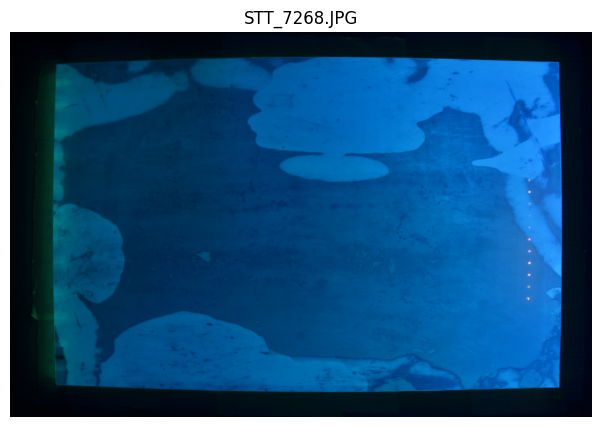

In [141]:
IMAGE_ROOT = "/Users/johannes/Desktop"
IMAGE_DIR = os.path.join(IMAGE_ROOT, "new_setup")
SAMPLE_IMAGE = os.path.join(IMAGE_DIR, "STT_7268.JPG")

img = Image.open(SAMPLE_IMAGE)
rgb = np.asarray(img)

print("size:", img.size, "mode:", img.mode, "array shape:", rgb.shape)

plt.figure(figsize=(8, 5))
plt.imshow(rgb)
plt.title(os.path.basename(SAMPLE_IMAGE))
plt.axis("off")
plt.show()

## 2. Compute per-pixel Lightness

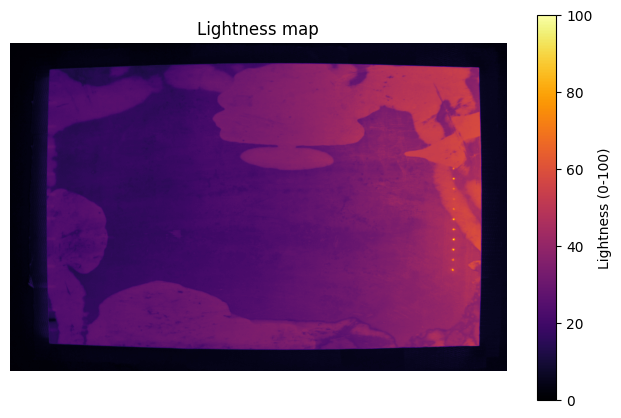

mean lightness: 23.12
std of lightness: 14.15


In [142]:
def lightness(rgb_array):
    """HSL Lightness of an HxWx3 uint8 RGB array, returned on a 0-100 scale."""
    arr = rgb_array[..., :3].astype(np.float32) / 255.0
    return (arr.max(axis=-1) + arr.min(axis=-1)) / 2 * 100


L = lightness(rgb)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(L, cmap="inferno", vmin=0, vmax=100)
ax.set_title("Lightness map")
ax.axis("off")
fig.colorbar(im, ax=ax, label="Lightness (0-100)")
plt.show()

print(f"mean lightness: {L.mean():.2f}")
print(f"std of lightness: {L.std():.2f}")

## 3. Grid analysis (mirrors the "divide into 64x64 squares" method from the slides)

This is what the uniformity/variance metric on slide 8 of the presentation is built from — split the image into small blocks, take the mean lightness of each block, and look at the spread of those block means.

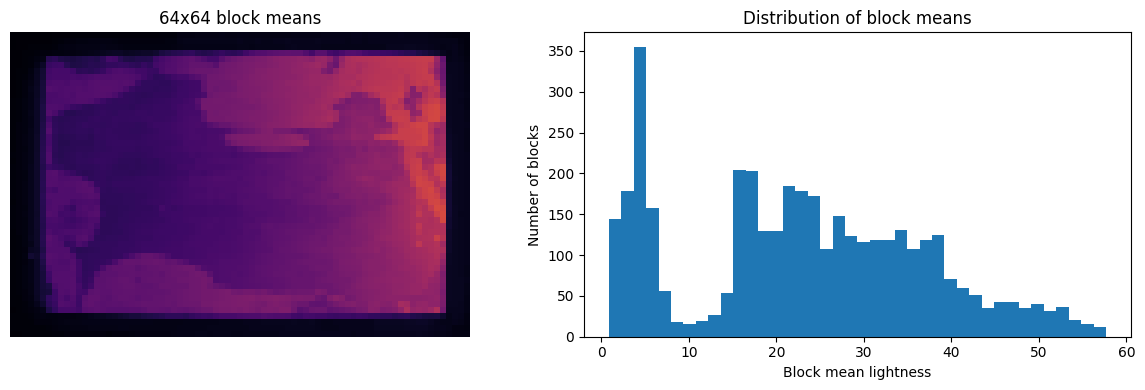

variance of block means (uniformity metric): 192.84


In [143]:
def block_means(lightness_array, block=64):
    h, w = lightness_array.shape
    h2, w2 = h - h % block, w - w % block
    trimmed = lightness_array[:h2, :w2]
    blocks = trimmed.reshape(h2 // block, block, w2 // block, block)
    return blocks.mean(axis=(1, 3))


means = block_means(L, block=64)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(means, cmap="inferno", vmin=0, vmax=100)
axes[0].set_title("64x64 block means")
axes[0].axis("off")
axes[1].hist(means.ravel(), bins=40)
axes[1].set_xlabel("Block mean lightness")
axes[1].set_ylabel("Number of blocks")
axes[1].set_title("Distribution of block means")
plt.tight_layout()
plt.show()

print(f"variance of block means (uniformity metric): {means.var():.2f}")

## 4. Saturation check

This directly answers one of the open questions from the presentation ("is there saturation in the camera images?"). JPEG is 8-bit and non-linear (gamma-corrected) — once a pixel hits 255 in a channel, all information above that brightness is gone and can't be recovered. A plate that's genuinely brighter than another one can look identical if both regions are clipped.

In these photos the blue channel is always the strongest (TPB emits blue), so it clips first, long before the pixel turns white. The check therefore counts pixels where **any** channel is at the ceiling, not just fully white pixels.

In [144]:
def saturation_fraction(rgb_array, threshold=250):
    """Percentage of pixels where at least one channel is at/near the 8-bit ceiling."""
    return 100 * np.mean(np.any(rgb_array[..., :3] >= threshold, axis=-1))


sat_pct = saturation_fraction(rgb)
print(f"{sat_pct:.2f}% of pixels have at least one clipped channel (>= 250)")

0.61% of pixels have at least one clipped channel (>= 250)


## 5. Per-tile analysis (new setup: 7 images per tile)

The list of tiles comes from the QC manifest (`MANIFEST`, exported from the "UV Photo QC" sheet): DSG number (the foil's label before lamination), ACL serial number (once laminated), folder, first and last image number, date. Columns are found by their header names. Each tile is labelled `ACL-26-xxxx (DSG-yy)`, or just `DSG-yy` for foils that haven't been laminated (yet). Rows without image numbers are skipped, and an empty folder falls back to `DEFAULT_FOLDER`, so the sheet can be filled in as the campaign progresses — just re-export it to the same path.

For each tile all 7 images are converted to Lightness, and we report the **sum** and **mean** of the per-image mean Lightness (try both against the scanner LY), plus the worst saturation fraction among its images.

**Cropping to the tile:** the zoom was different in each session so far (18 mm on Oct 7, 22 mm on the morning of Oct 8, 21 mm in the afternoon), and the tile position shifts a little between tiles. So the tile is found automatically in each tile's 7-image average: pixels brighter than half the median count as tile, and the box spans the rows/columns that are at least 80% tile. The box is then shrunk by `CROP_MARGIN` on each side to stay clear of the edges. The printed `box` column shows what was used; if detection gets a tile wrong, put a hand-measured box for it in `CROPS`, which takes precedence. Note that at 22 mm the tile is larger than the frame, so those boxes are the frame, not the tile edges.

**Sanity checks:** a warning is printed if the image date doesn't match the manifest date, or if an image in the range is as bright as a room-light label photo (usually means an off-by-one in the image numbers).

In [145]:
MANIFEST = "/Users/johannes/Desktop/Master Thesis/data/UV Photo QC - Sheet1.csv"
DEFAULT_FOLDER = "new_setup"  # used when the folder column is empty
IMAGES_PER_TILE = 7
LABEL_PHOTO_L = 75  # images brighter than this on average look like a room-light label photo

CROPS = {}  # optional hand-measured (row_start, row_stop, col_start, col_stop) per tile, overrides detection
CROP_MARGIN = 0.01  # shrink the detected tile box by this fraction on each side

BLOCK = 64  # side length in pixels of the grid squares used for the heatmaps
SMOOTH_DOWNSAMPLE = 4  # keep every 4th pixel of the averaged map for the per-pixel plot
SCAN_GRID = (10, 16)  # rows x cols across the cropped tile, matching the scanner positions


def parse_date(text):
    for fmt in ("%d.%m.%Y", "%d.%m.%y"):
        try:
            return datetime.strptime(text, fmt).date()
        except ValueError:
            pass
    return None


def read_manifest(path):
    with open(path, newline="", encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))
    header = next((i for i, r in enumerate(rows) if "ACL Serial number" in [c.strip() for c in r]), None)
    if header is None:
        raise ValueError(f"no header row with 'ACL Serial number' found in {path}")
    columns = [c.strip() for c in rows[header]]
    tiles = {}
    for r in rows[header + 1:]:
        row = dict(zip(columns, (c.strip() for c in r)))
        dsg, acl = row.get("DSG number", ""), row.get("ACL Serial number", "")
        first, last = row.get("first image", ""), row.get("last image", "")
        if not (first and last and (dsg or acl)):
            continue
        label = f"{acl} ({dsg})" if acl and dsg else acl or dsg
        tiles[label] = {"dsg": dsg, "acl": acl, "folder": row.get("folder name") or DEFAULT_FOLDER,
                        "first": int(first), "last": int(last), "date": row.get("date", ""),
                        "notes": row.get("notes", "")}
    return tiles


def tile_paths(folder, first, last):
    paths = [os.path.join(IMAGE_ROOT, folder, f"STT_{n}.JPG") for n in range(first, last + 1)]
    if len(paths) != IMAGES_PER_TILE:
        raise ValueError(f"images {first}-{last} are {len(paths)} images, expected {IMAGES_PER_TILE}")
    missing = [os.path.basename(p) for p in paths if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(f"missing images in {os.path.join(IMAGE_ROOT, folder)}: {missing}")
    return paths


def capture_date(path):
    raw = Image.open(path).getexif().get_ifd(0x8769).get(36867)  # EXIF DateTimeOriginal
    return datetime.strptime(raw, "%Y:%m:%d %H:%M:%S").date() if raw else None


def detect_tile_box(paths, scale=4):
    """Bounding box of the bright tile in the average of the images, found at 1/scale resolution."""
    L_small = np.mean([lightness(np.asarray(Image.open(p).reduce(scale))) for p in paths], axis=0)
    is_tile = L_small > 0.5 * np.median(L_small)
    rows = np.where(is_tile.mean(axis=1) > 0.8)[0]
    cols = np.where(is_tile.mean(axis=0) > 0.8)[0]
    r0, r1, c0, c1 = rows.min(), rows.max() + 1, cols.min(), cols.max() + 1
    dr, dc = CROP_MARGIN * (r1 - r0), CROP_MARGIN * (c1 - c0)
    return tuple(int(round(v * scale)) for v in (r0 + dr, r1 - dr, c0 + dc, c1 - dc))


def cell_means(arr, shape):
    """Mean of arr over an n_rows x n_cols grid of near-equal cells covering the whole array."""
    row_edges = np.linspace(0, arr.shape[0], shape[0] + 1).astype(int)
    col_edges = np.linspace(0, arr.shape[1], shape[1] + 1).astype(int)
    return np.array([[arr[r0:r1, c0:c1].mean() for c0, c1 in zip(col_edges[:-1], col_edges[1:])]
                     for r0, r1 in zip(row_edges[:-1], row_edges[1:])])


manifest = read_manifest(MANIFEST)
print(f"{len(manifest)} tiles with images in the manifest\n")

results = {}
for tile, m in manifest.items():
    paths = tile_paths(m["folder"], m["first"], m["last"])
    shot_date = capture_date(paths[0])
    if m["date"] and parse_date(m["date"]) != shot_date:
        print(f"WARNING {tile}: manifest says {m['date']}, images were taken {shot_date}")
    r0, r1, c0, c1 = box = CROPS.get(tile) or detect_tile_box(paths)
    per_image_mean, per_image_sat = [], []
    L_sum = None
    for p in paths:
        arr = np.asarray(Image.open(p))[r0:r1, c0:c1]
        L_i = lightness(arr)
        per_image_mean.append(L_i.mean())
        per_image_sat.append(saturation_fraction(arr))
        L_sum = L_i if L_sum is None else L_sum + L_i
    too_bright = [os.path.basename(p) for p, v in zip(paths, per_image_mean) if v > LABEL_PHOTO_L]
    if too_bright:
        print(f"WARNING {tile}: {too_bright} look like label photos (mean L > {LABEL_PHOTO_L}), check the image range")
    L_avg = L_sum / len(per_image_mean)
    results[tile] = {
        "dsg": m["dsg"],
        "acl": m["acl"],
        "notes": m["notes"],
        "images": f"{m['first']}-{m['last']}",
        "box": box,
        "per_image_mean": per_image_mean,
        "per_image_sat": per_image_sat,
        "sum": sum(per_image_mean),
        "mean": np.mean(per_image_mean),
        "heatmap": block_means(L_avg, BLOCK),
        "smooth": L_avg[::SMOOTH_DOWNSAMPLE, ::SMOOTH_DOWNSAMPLE],
        "scan_grid": cell_means(L_avg, SCAN_GRID),
    }

print(f"{'tile':<24s} {'images':<10s} {'box (r0, r1, c0, c1)':<24s} {'sum L':>8s} {'mean L':>7s} {'max sat %':>9s}   per-image mean L")
for tile, r in results.items():
    per_img = " ".join(f"{v:5.1f}" for v in r["per_image_mean"])
    box = str(tuple(r["box"]))
    print(f"{tile:<24s} {r['images']:<10s} {box:<24s} {r['sum']:8.2f} {r['mean']:7.2f} {max(r['per_image_sat']):9.2f}   {per_img}")

38 tiles with images in the manifest

tile                     images     box (r0, r1, c0, c1)        sum L  mean L max sat %   per-image mean L
DSG-01                   7607-7613  (48, 3176, 68, 4736)       125.80   17.97      0.14    12.7  15.9  10.8  10.7  24.6  28.1  22.9
DSG-02                   7615-7621  (436, 2752, 642, 4010)     119.34   17.05      0.08    14.8  32.5  24.8   9.5   9.8  16.7  11.3
DSG-03                   7623-7629  (32, 3168, 48, 4800)       176.93   25.28      0.13    25.3  20.9  20.6  17.6  27.3  25.0  40.2
DSG-04                   7631-7637  (76, 3184, 77, 4831)       159.71   22.82      0.14    38.5  26.6  22.8  15.2  18.6  18.3  19.8
DSG-05                   7639-7645  (32, 3168, 191, 4765)      141.84   20.26      0.18    19.7  18.3  15.2  14.6  28.3  22.8  23.1
DSG-06                   7647-7653  (270, 3190, 405, 4843)     150.49   21.50      0.19    20.8  35.5  25.5  16.1  11.5  19.7  21.5
DSG-19                   7655-7661  (51, 3045, 75, 4721)       

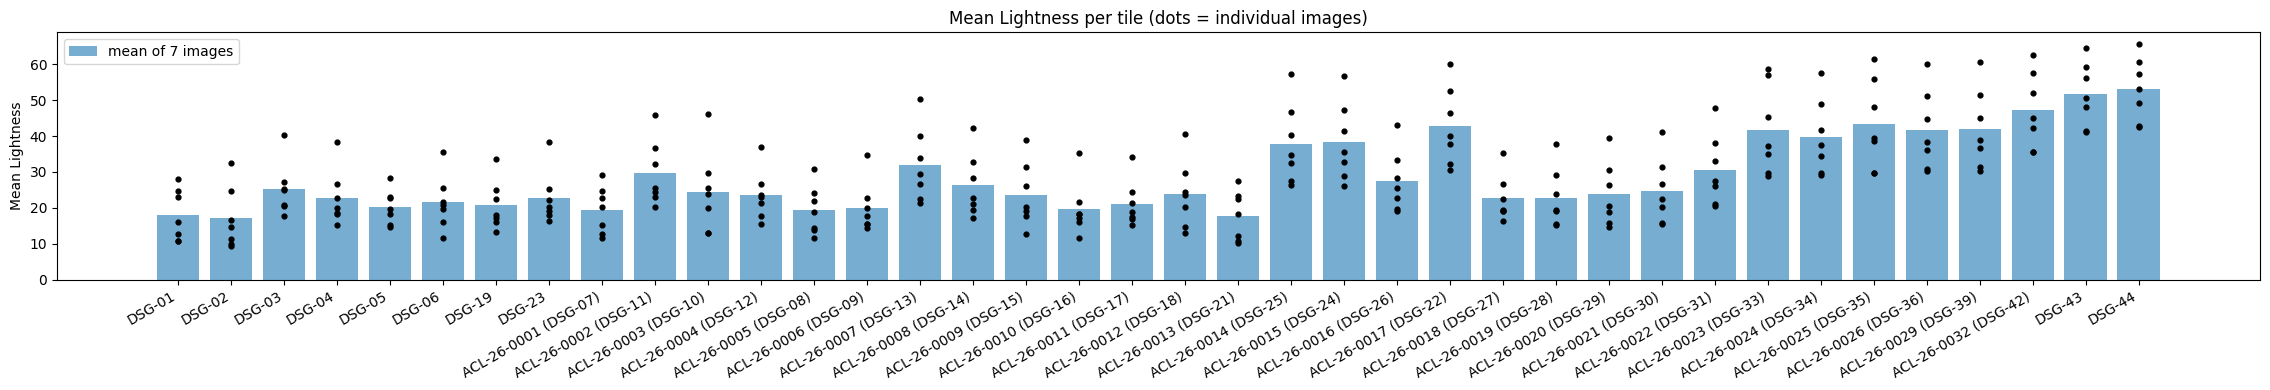

In [146]:
names = list(results)
x = np.arange(len(names))

fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(results)), 4))
ax.bar(x, [results[t]["mean"] for t in names], color="tab:blue", alpha=0.6, label="mean of 7 images")
for xi, t in zip(x, names):
    ax.scatter(np.full(len(results[t]["per_image_mean"]), xi), results[t]["per_image_mean"], color="k", s=12, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("Mean Lightness")
ax.set_title("Mean Lightness per tile (dots = individual images)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Lightness heatmaps per tile (64x64 pixel grid)

Each tile's 7 images are averaged into one Lightness map, which is then cut into `BLOCK` x `BLOCK` pixel squares (64 by default, same as the slides). Each square is coloured by its mean Lightness. All tiles share one colour scale (1st–99th percentile across all tiles), so colours are directly comparable between tiles — keep in mind the day-1 and day-2 tiles are at different zoom, so one square covers a different physical area.

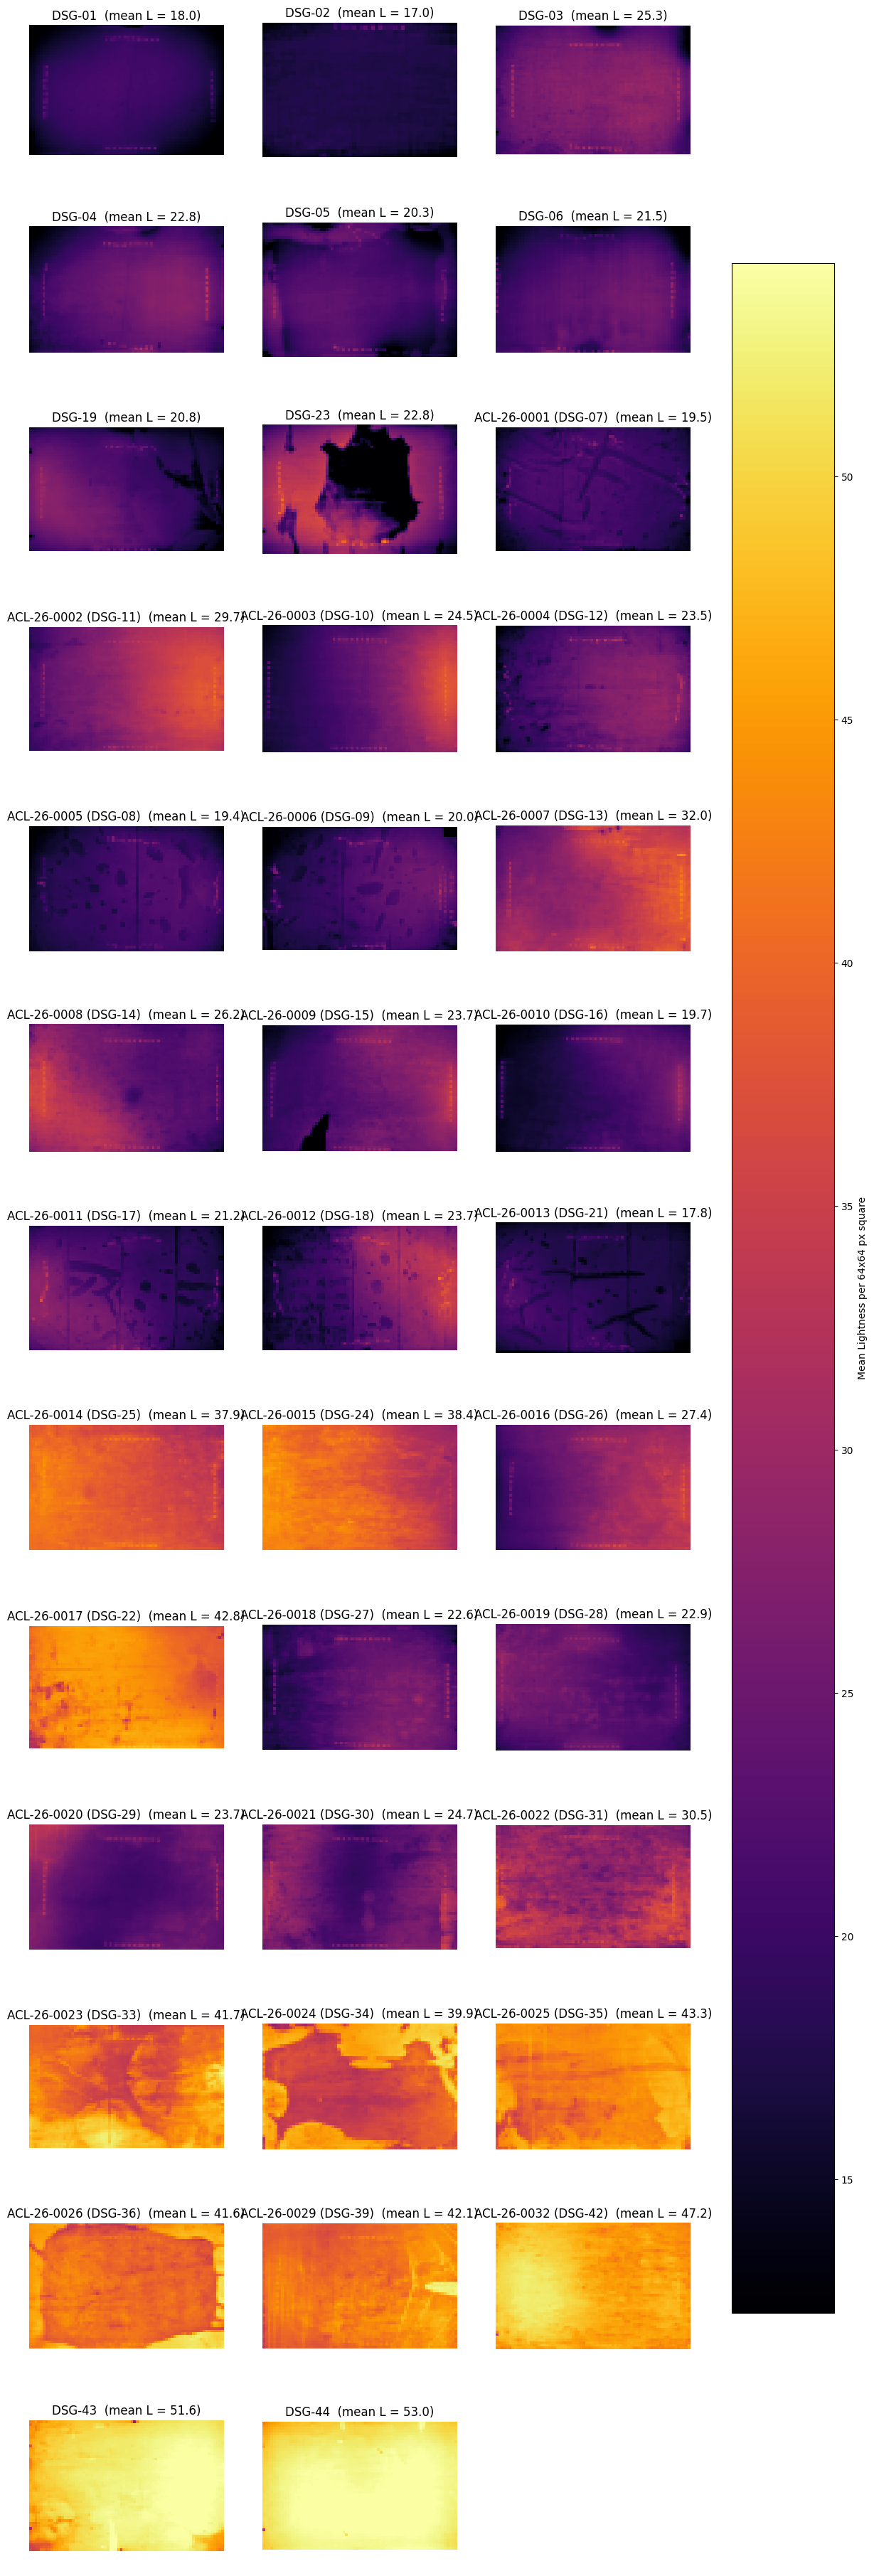

In [147]:
all_values = np.concatenate([r["heatmap"].ravel() for r in results.values()])
vmin, vmax = np.percentile(all_values, [1, 99])

ncols = 3
nrows = int(np.ceil(len(results) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)
for ax, (tile, r) in zip(axes.flat, results.items()):
    im = ax.imshow(r["heatmap"], cmap="inferno", vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(f"{tile}  (mean L = {r['mean']:.1f})")
    ax.axis("off")
for ax in axes.flat[len(results):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, label=f"Mean Lightness per {BLOCK}x{BLOCK} px square", shrink=0.8)
plt.show()

### One tile on the scan grid, next to the per-pixel map

The cropped tile is divided into `SCAN_GRID` = 10 x 16 cells (the scanner's resolution), and each cell shows the mean Lightness of all its pixels at full resolution. Unlike the 64 px blocks above, the cells are defined by count, not by pixel size, so every tile gets exactly 10 x 16 cells regardless of zoom and no edge pixels are dropped.

Next to the grid is the per-pixel Lightness map of the same tile (averaged over the 7 images), drawn with the same colour scale. Both are rotated by 90° (`ROTATION_K`) so the long edge points up.

For the cells to correspond to actual scan positions, the crop has to sit exactly on the tile edges, and the orientation has to match the scan map's. The day-1 crop boxes in `CROPS` are rough, and in the day-2 images the tile reaches to or just past the frame edges, so for now the correspondence is approximate.


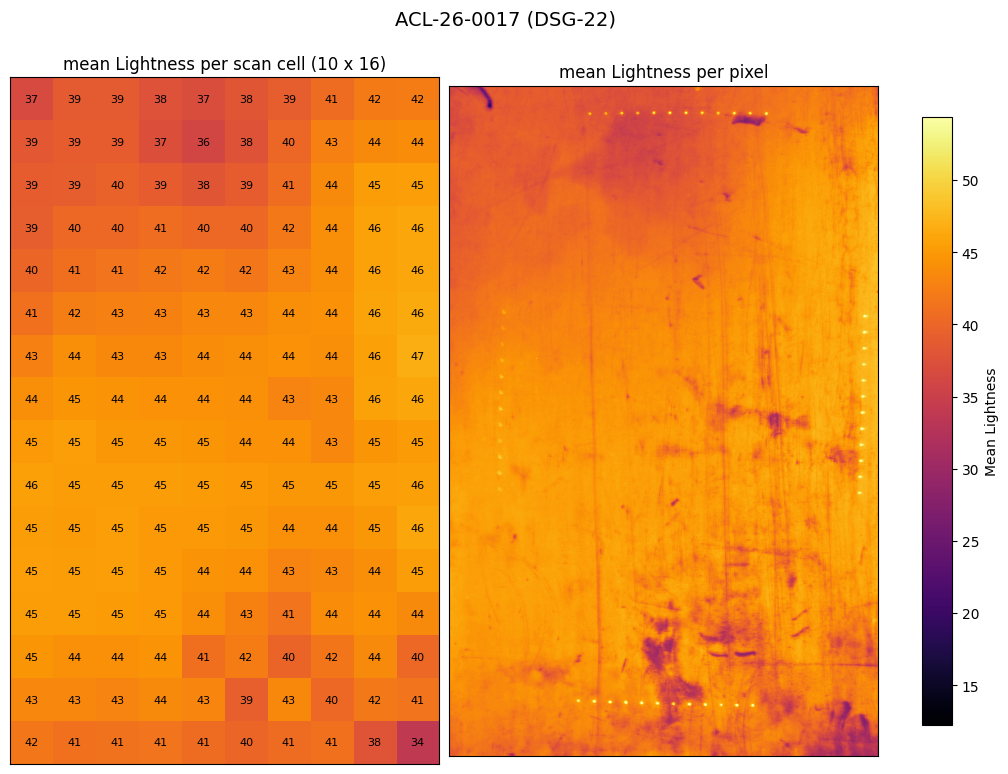

In [148]:
ANNOTATE_TILE = "ACL-26-0017"
ROTATION_K = 1  # number of 90° counter-clockwise turns; -1 for clockwise, 0 for none

annotate_key = next(k for k in results if ANNOTATE_TILE in k)  # ACL serial or DSG number both work
r = results[annotate_key]
grid = np.rot90(r["scan_grid"], ROTATION_K)
smooth = np.rot90(r["smooth"], ROTATION_K)

fig, (ax_grid, ax_smooth) = plt.subplots(1, 2, figsize=(10, 8), layout="constrained")
im = ax_grid.imshow(grid, cmap="inferno", vmin=vmin, vmax=vmax, interpolation="nearest")
for (row, col), value in np.ndenumerate(grid):
    ax_grid.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=8,
                 color="white" if value < (vmin + vmax) / 2 else "black")
ax_grid.set_title(f"mean Lightness per scan cell ({SCAN_GRID[0]} x {SCAN_GRID[1]})")
ax_smooth.imshow(smooth, cmap="inferno", vmin=vmin, vmax=vmax)
ax_smooth.set_title("mean Lightness per pixel")
for ax in (ax_grid, ax_smooth):
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(annotate_key, fontsize=14)
fig.colorbar(im, ax=[ax_grid, ax_smooth], label="Mean Lightness", shrink=0.8)
plt.show()

## 7. Stability test (repeatability of the photo measurement)

How much does the mean Lightness of the *same* tile change if the whole 7-image measurement is repeated? That spread is the real measurement error on Lightness. It replaces the placeholder error in the correlation and tells you how large a difference between two tiles is significant.

**Protocol**
- Pick one tile with average Lightness and measure it 5 times (7 images each), with a label photo before each repeat.
- **Take the tile out and put it back between repeats.** Placement is part of the real measurement, so it should be part of the error. If you also want to separate placement from camera/LED noise, add one extra repeat without touching the tile.
- Keep zoom and exposure the same. If the order of the 7 LED configurations changes between repeats, the per-configuration comparison still works: configurations are matched by brightness rank (darkest with darkest, and so on). Spreading the repeats over a few hours (or two days) also catches drift.
- Enter each repeat's first and last image number in `STABILITY_RUNS` below. The tile doesn't need to be in the sheet for this.

With 5 repeats the spread itself is only known to roughly ±35%, so treat the result as an estimate, not an exact number.

ACL-26-0007: 10 repeats

repeat  images      mean L   per-image mean L
1       7413-7419    32.00    50.3  39.9  34.0  22.4  21.4  26.6  29.4
2       7518-7524    31.52    50.3  39.8  34.7  19.5  22.3  25.8  28.2
3       7525-7531    31.65    28.3  26.2  22.9  20.2  34.4  50.0  39.4
4       7532-7538    31.68    39.4  49.9  34.4  20.2  22.8  26.4  28.7
5       7540-7546    31.86    28.7  26.4  23.0  20.1  35.3  49.9  39.5
6       7547-7553    31.57    39.3  49.6  34.3  19.4  23.4  26.8  28.2
7       7554-7560    31.64    29.3  26.1  22.8  20.2  34.0  49.9  39.2
8       7561-7567    31.34    39.2  49.8  35.2  19.3  22.1  25.7  28.0
9       7568-7574    31.43    28.2  26.0  22.6  19.9  34.2  49.8  39.3
10      7575-7581    31.23    39.1  49.6  34.2  19.4  22.3  26.0  28.1

mean Lightness over repeats:  31.59
std between repeats:          0.23  (0.7%)
max - min:                    0.77
placeholder error used so far (std of 7 images / sqrt 7): 3.96
std between repeats per LED configuration

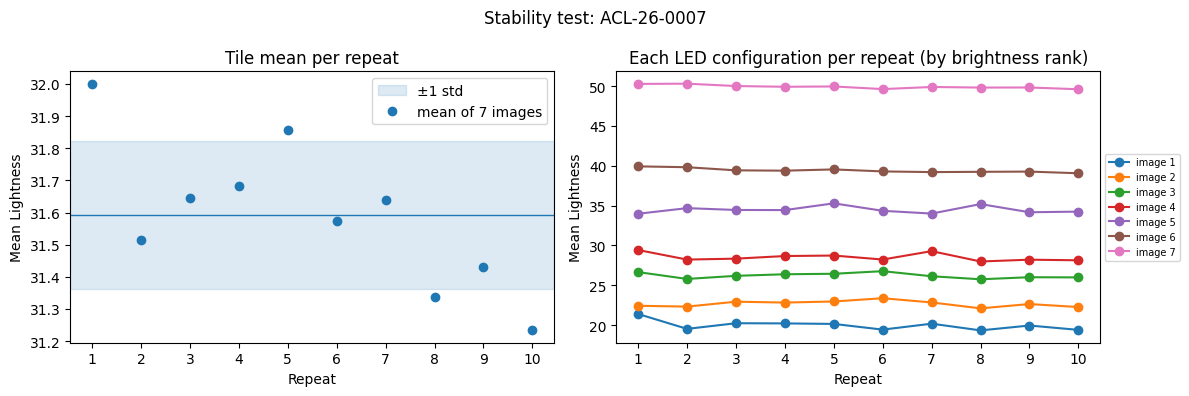

In [149]:
STABILITY_TILE = "ACL-26-0007"  # tile used for the repeats (only used for labels and CROPS)
STABILITY_FOLDER = DEFAULT_FOLDER
STABILITY_RUNS = [  # (first image, last image) of each repeat, in the order they were taken
     (7413, 7419),
     (7518, 7524),
     (7525, 7531),
     (7532, 7538),
     (7540, 7546),
     (7547, 7553),
     (7554, 7560),
     (7561, 7567),
     (7568, 7574),
     (7575, 7581),
]

if len(STABILITY_RUNS) < 2:
    print("Fill in STABILITY_RUNS with at least 2 repeats of the same tile to run the stability test.")
else:
    run_images = []
    for first, last in STABILITY_RUNS:
        paths = tile_paths(STABILITY_FOLDER, first, last)
        r0, r1, c0, c1 = CROPS.get(STABILITY_TILE) or detect_tile_box(paths)
        run_images.append([lightness(np.asarray(Image.open(p))[r0:r1, c0:c1]).mean() for p in paths])
    run_images = np.array(run_images)  # shape (repeats, 7)
    run_means = run_images.mean(axis=1)

    stab_mean = run_means.mean()
    stab_std = run_means.std(ddof=1)
    stab_rel = stab_std / stab_mean
    placeholder = np.mean(run_images.std(axis=1, ddof=1) / np.sqrt(run_images.shape[1]))

    print(f"{STABILITY_TILE}: {len(STABILITY_RUNS)} repeats\n")
    print(f"{'repeat':<7s} {'images':<10s} {'mean L':>7s}   per-image mean L")
    for k, ((first, last), m, imgs) in enumerate(zip(STABILITY_RUNS, run_means, run_images), start=1):
        print(f"{k:<7d} {first}-{last:<5d} {m:7.2f}   " + " ".join(f"{v:5.1f}" for v in imgs))
    print(f"\nmean Lightness over repeats:  {stab_mean:.2f}")
    print(f"std between repeats:          {stab_std:.2f}  ({100 * stab_rel:.1f}%)")
    print(f"max - min:                    {np.ptp(run_means):.2f}")
    print(f"placeholder error used so far (std of 7 images / sqrt 7): {placeholder:.2f}")
    print("std between repeats per LED configuration, matched by brightness rank (darkest..brightest): "
          + " ".join(f"{v:4.2f}" for v in np.sort(run_images, axis=1).std(axis=0, ddof=1)))
    print(f"\nTwo tiles measured once each differ significantly (2 sigma) if their Lightness differs by "
          f"more than 2*sqrt(2)*std = {2 * np.sqrt(2) * stab_std:.2f} (at this Lightness).")
    print(f"-> set LIGHTNESS_REL_ERR = {stab_rel:.3f} in section 8")

    repeats = np.arange(1, len(run_means) + 1)
    fig, (ax_mean, ax_cfg) = plt.subplots(1, 2, figsize=(12, 4))
    ax_mean.axhspan(stab_mean - stab_std, stab_mean + stab_std, color="tab:blue", alpha=0.15, label="±1 std")
    ax_mean.axhline(stab_mean, color="tab:blue", lw=1)
    ax_mean.plot(repeats, run_means, "o", color="tab:blue", label="mean of 7 images")
    ax_mean.set_xlabel("Repeat")
    ax_mean.set_ylabel("Mean Lightness")
    ax_mean.set_title("Tile mean per repeat")
    ax_mean.set_xticks(repeats)
    ax_mean.legend()
    ranked = np.sort(run_images, axis=1)
    for j in range(ranked.shape[1]):
        ax_cfg.plot(repeats, ranked[:, j], "o-", label=f"image {j + 1}")
    ax_cfg.set_xlabel("Repeat")
    ax_cfg.set_ylabel("Mean Lightness")
    ax_cfg.set_title("Each LED configuration per repeat (by brightness rank)")
    ax_cfg.set_xticks(repeats)
    ax_cfg.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle(f"Stability test: {STABILITY_TILE}")
    plt.tight_layout()
    plt.show()

## 8. Correlation with scanner light yield

Mean Lightness per tile (section 5) against the total LY from the scanner. Only laminated tiles whose ACL serial number has an entry in `LIGHT_YIELD` enter the correlation and the fit, so this works while the imaging and scanning campaigns are still incomplete.

Imaged tiles without a scan get a **predicted** LY from the fit, shown in a separate plot below the correlation: laminated ACLs that haven't been scanned, foils that aren't laminated yet (DSG number only), and foils rejected at visual inspection (listed in `REJECTED_VISUAL`). The prediction uncertainty is the standard deviation of the scanned tiles around the fit, which is the honest measure of how well Lightness predicts LY. Predictions outside the Lightness range of the scanned ACLs are extrapolations of the straight line and are flagged as such in the printout. Below Lightness ≈ 14 the line even predicts a negative LY, which just means "darker than any scanned tile".

**Caveat for foils:** the calibration comes from photos of *laminated* ACLs. A bare foil may look different to the camera (no WLS plastic behind it, different background), so foil predictions assume that lamination doesn't change the Lightness. Photographing the same foil before and after lamination checks this directly.

**Error bars**
- **LY:** 1.6% per tile (scanner systematic; statistical is negligible). If that 1.6% is a common scale uncertainty shared by all tiles rather than tile-to-tile reproducibility, it shifts every point together and doesn't affect the correlation — set `LY_REL_ERR = 0` in that case.
- **Lightness:** until the camera's repeatability is measured, the default is the standard error of the 7 per-image means (std / √7). The 7 images are different LED configurations, so this measures how different the configurations are, not true measurement noise — treat it as a placeholder. Once the stability test (section 7) has been done, set `LIGHTNESS_REL_ERR` to the relative spread it prints.

**Statistics:** Pearson r (linear), Spearman ρ (rank-based — robust because JPEG brightness is not linear in light, gamma ≈ 2.2), and a straight-line fit using orthogonal distance regression (`scipy.odr`), which accounts for errors on both axes.

In [150]:
LIGHT_YIELD = {  # total LY from the scanner [ADC]
    "ACL-26-0001": 2.48e7, "ACL-26-0002": 4.41e7, "ACL-26-0003": 5.14e7, "ACL-26-0004": 3.11e7,
    "ACL-26-0005": 3.14e7, "ACL-26-0006": 2.98e7, "ACL-26-0007": 9.12e7, "ACL-26-0008": 4.50e7,
    "ACL-26-0009": 6.27e7, "ACL-26-0010": 5.74e7, "ACL-26-0011": 3.66e7, "ACL-26-0012": 3.94e7,
    "ACL-26-0013": 3.09e7, "ACL-26-0014": 1.53e8, "ACL-26-0015": 1.15e8, "ACL-26-0016": 7.93e7,
    "ACL-26-0017": 9.65e7, "ACL-26-0018": 5.02e7, "ACL-26-0019": 4.86e7, "ACL-26-0020": 7.36e7,
    "ACL-26-0021": 6.87e7, "ACL-26-0022": 8.25e7, "ACL-26-0023": 1.25e8, "ACL-26-0024": 1.22e8,
    "ACL-26-0025": 1.18e8, "ACL-26-0026": 9.15e7, "ACL-26-0027": 1.44e8, "ACL-26-0028": 1.30e8,
    "ACL-26-0029": 1.24e8, "ACL-26-0030": 1.42e8, "ACL-26-0031": 1.62e8,
}

REJECTED_VISUAL = {  # foils that failed visual inspection and were never laminated
    "DSG-01", "DSG-02", "DSG-03", "DSG-04", "DSG-05", "DSG-06", "DSG-19", "DSG-23",
}

LY_REL_ERR = 0.016
LIGHTNESS_REL_ERR = 0.007 

tile                             mean L     LY [10^6 ADC]
ACL-26-0001 (DSG-07)      19.47 ±  0.14      24.8 ±  0.4
ACL-26-0002 (DSG-11)      29.72 ±  0.21      44.1 ±  0.7
ACL-26-0003 (DSG-10)      24.45 ±  0.17      51.4 ±  0.8
ACL-26-0004 (DSG-12)      23.53 ±  0.16      31.1 ±  0.5
ACL-26-0005 (DSG-08)      19.36 ±  0.14      31.4 ±  0.5
ACL-26-0006 (DSG-09)      20.04 ±  0.14      29.8 ±  0.5
ACL-26-0007 (DSG-13)      32.00 ±  0.22      91.2 ±  1.5
ACL-26-0008 (DSG-14)      26.24 ±  0.18      45.0 ±  0.7
ACL-26-0009 (DSG-15)      23.66 ±  0.17      62.7 ±  1.0
ACL-26-0010 (DSG-16)      19.73 ±  0.14      57.4 ±  0.9
ACL-26-0011 (DSG-17)      21.18 ±  0.15      36.6 ±  0.6
ACL-26-0012 (DSG-18)      23.71 ±  0.17      39.4 ±  0.6
ACL-26-0013 (DSG-21)      17.76 ±  0.12      30.9 ±  0.5
ACL-26-0014 (DSG-25)      37.92 ±  0.27     153.0 ±  2.4
ACL-26-0015 (DSG-24)      38.41 ±  0.27     115.0 ±  1.8
ACL-26-0016 (DSG-26)      27.36 ±  0.19      79.3 ±  1.3
ACL-26-0017 (DSG-22)      42.7

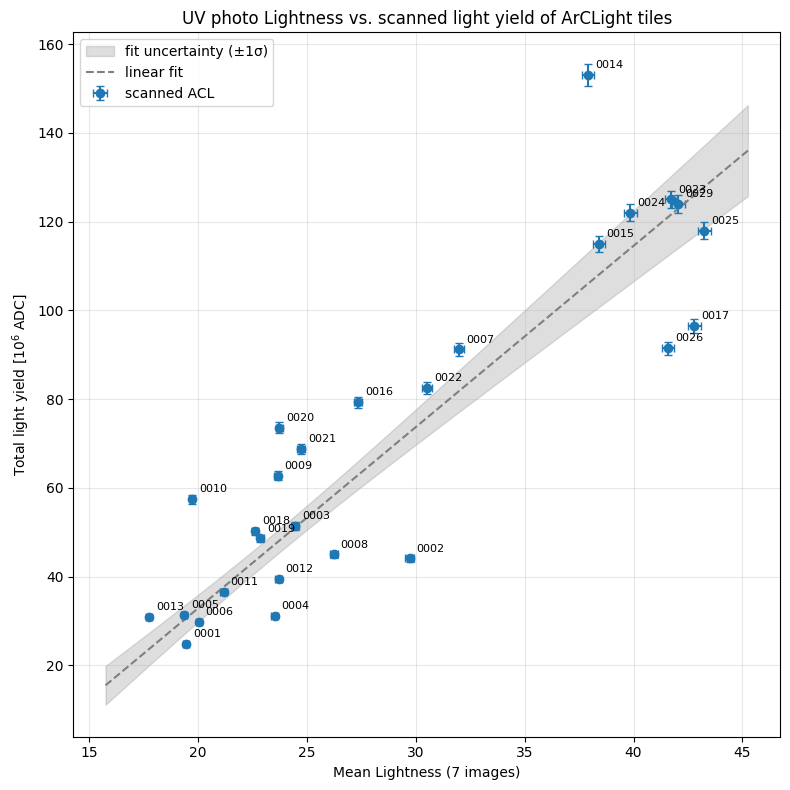

In [151]:
from scipy import odr, stats


def lightness_error(r):
    if LIGHTNESS_REL_ERR is None:
        return np.std(r["per_image_mean"], ddof=1) / np.sqrt(len(r["per_image_mean"]))
    return LIGHTNESS_REL_ERR * r["mean"]


def fit_band(fit_result, x):
    """1 sigma uncertainty of the fitted line at x, from the slope/intercept covariance."""
    cov = fit_result.cov_beta * fit_result.res_var
    return np.sqrt(x ** 2 * cov[0, 0] + cov[1, 1] + 2 * x * cov[0, 1])


scanned = [t for t, r in results.items() if r["acl"] in LIGHT_YIELD]
not_scanned = [t for t in results if t not in scanned]
if len(scanned) < 3:
    raise ValueError(f"need at least 3 tiles with both images and LY, have {len(scanned)}")

L_mean = np.array([results[t]["mean"] for t in scanned])
L_err = np.array([lightness_error(results[t]) for t in scanned])
ly = np.array([LIGHT_YIELD[results[t]["acl"]] for t in scanned])
ly_err = LY_REL_ERR * ly

pearson = stats.pearsonr(L_mean, ly)
spearman = stats.spearmanr(L_mean, ly)

slope0, intercept0 = np.polyfit(L_mean, ly, 1)
fit = odr.ODR(odr.RealData(L_mean, ly, sx=L_err, sy=ly_err),
              odr.Model(lambda b, x: b[0] * x + b[1]), beta0=[slope0, intercept0]).run()
(slope, intercept), (slope_err, intercept_err) = fit.beta, fit.sd_beta
ndf = len(scanned) - 2
residual_std = np.sqrt(np.sum((ly - (slope * L_mean + intercept)) ** 2) / ndf)

scale = 1e6
print(f"{'tile':<24s} {'mean L':>14s} {'LY [10^6 ADC]':>17s}")
for t, l, le, y, ye in zip(scanned, L_mean, L_err, ly, ly_err):
    print(f"{t:<24s} {l:6.2f} ± {le:5.2f}   {y / scale:7.1f} ± {ye / scale:4.1f}")
print(f"\nn = {len(scanned)} scanned tiles")
print(f"Pearson r    = {pearson.statistic:+.3f}  (p = {pearson.pvalue:.3g})")
print(f"Spearman rho = {spearman.statistic:+.3f}  (p = {spearman.pvalue:.3g})")
print(f"fit: LY = ({slope:.3e} ± {slope_err:.1e}) * L + ({intercept:.3e} ± {intercept_err:.1e})")
if ndf > 0:
    print(f"reduced chi2 = {fit.res_var:.2f}  (ndf = {ndf})")
print(f"residual std of scanned tiles around the fit: {residual_std / scale:.1f} x 10^6 ADC")

x_line = np.linspace(L_mean.min() - 2, L_mean.max() + 2, 100)
fig, ax = plt.subplots(figsize=(8, 8))
ax.errorbar(L_mean, ly / scale, xerr=L_err, yerr=ly_err / scale, fmt="o", capsize=3, color="tab:blue",
            label="scanned ACL")
for t, l, y in zip(scanned, L_mean, ly):
    ax.annotate(results[t]["acl"].replace("ACL-26-", ""), (l, y / scale), textcoords="offset points",
                xytext=(5, 5), fontsize=8)
y_line = slope * x_line + intercept
band = fit_band(fit, x_line)
ax.fill_between(x_line, (y_line - band) / scale, (y_line + band) / scale, color="tab:gray", alpha=0.25,
                label="fit uncertainty (±1σ)")
ax.plot(x_line, y_line / scale, "--", color="tab:gray", label="linear fit")
ax.set_xlabel("Mean Lightness (7 images)")
ax.set_ylabel("Total light yield [$10^6$ ADC]")
ax.set_title("UV photo Lightness vs. scanned light yield of ArCLight tiles")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

LY predicted from the fit [10^6 ADC], ± expected spread of a single tile (sqrt(residual std^2 + fit uncertainty^2)); scanned ACLs cover L = 17.8 to 43.3

laminated, not scanned (predicted):
  ACL-26-0032 (DSG-42)     L =  47.20 ± 0.33   LY ≈  144.0 ± 20.9  (extrapolated)

foil, not laminated (predicted):
  DSG-43                   L =  51.60 ± 0.36   LY ≈  161.9 ± 22.0  (extrapolated)
  DSG-44                   L =  53.02 ± 0.37   LY ≈  167.8 ± 22.4  (extrapolated)

foil, rejected at visual inspection (predicted):
  DSG-01                   L =  17.97 ± 0.13   LY ≈   24.5 ± 18.1
  DSG-02                   L =  17.05 ± 0.12   LY ≈   20.8 ± 18.1  (extrapolated)
  DSG-03                   L =  25.28 ± 0.18   LY ≈   54.4 ± 17.9
  DSG-04                   L =  22.82 ± 0.16   LY ≈   44.3 ± 17.9
  DSG-05                   L =  20.26 ± 0.14   LY ≈   33.9 ± 18.0
  DSG-06                   L =  21.50 ± 0.15   LY ≈   39.0 ± 17.9
  DSG-19                   L =  20.78 ± 0.15   LY ≈   36.0 ± 18.0
  

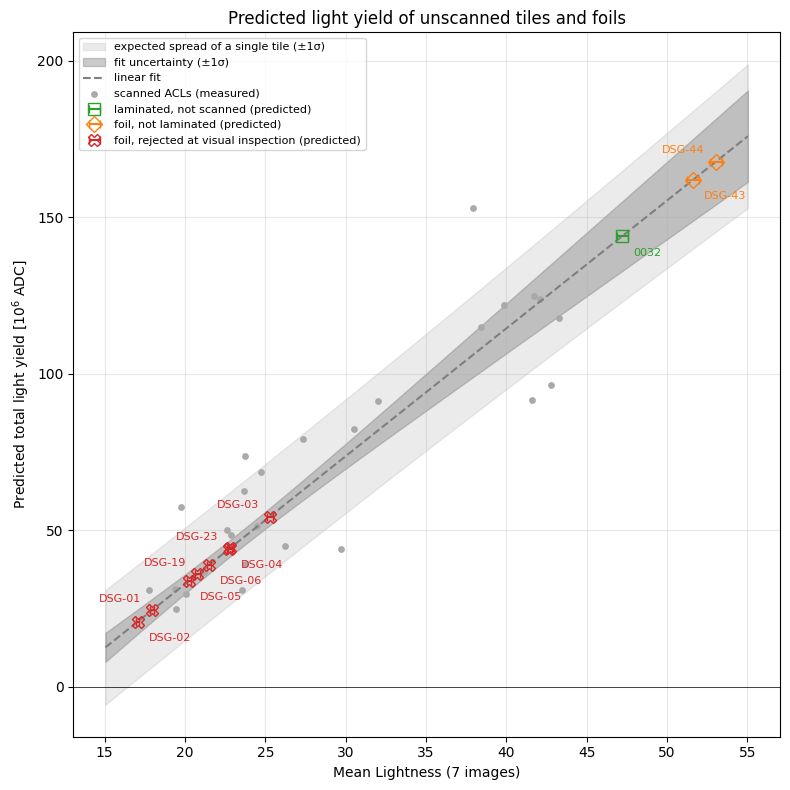

In [152]:
PREDICTION_GROUPS = [  # (group, marker, colour, legend label)
    ("laminated", "s", "tab:green", "laminated, not scanned (predicted)"),
    ("foil", "D", "tab:orange", "foil, not laminated (predicted)"),
    ("rejected", "X", "tab:red", "foil, rejected at visual inspection (predicted)"),
]


def prediction_group(r):
    if r["dsg"] in REJECTED_VISUAL:
        return "rejected"
    return "laminated" if r["acl"] else "foil"


def short_name(r):
    return r["acl"].replace("ACL-26-", "") if r["acl"] else r["dsg"]


L_lo, L_hi = L_mean.min(), L_mean.max()
print(f"LY predicted from the fit [10^6 ADC], ± expected spread of a single tile "
      f"(sqrt(residual std^2 + fit uncertainty^2)); "
      f"scanned ACLs cover L = {L_lo:.1f} to {L_hi:.1f}")
for group, _, _, label in PREDICTION_GROUPS:
    members = [t for t in not_scanned if prediction_group(results[t]) == group]
    if not members:
        continue
    print(f"\n{label}:")
    for t in members:
        l = results[t]["mean"]
        pred = slope * l + intercept
        flag = "" if L_lo <= l <= L_hi else "  (extrapolated)"
        notes = f"  [{results[t]['notes']}]" if results[t]["notes"] else ""
        pred_err = np.sqrt(residual_std ** 2 + fit_band(fit, l) ** 2)
        print(f"  {t:<24s} L = {l:6.2f} ± {lightness_error(results[t]):4.2f}   "
              f"LY ≈ {pred / scale:6.1f} ± {pred_err / scale:4.1f}{flag}{notes}")

pred_L = [results[t]["mean"] for t in not_scanned] + list(L_mean)
x_pred = np.linspace(min(pred_L) - 2, max(pred_L) + 2, 100)
y_pred = slope * x_pred + intercept

fig, ax = plt.subplots(figsize=(8, 8))
band_fit = fit_band(fit, x_pred)
band_tile = np.sqrt(residual_std ** 2 + band_fit ** 2)
ax.fill_between(x_pred, (y_pred - band_tile) / scale, (y_pred + band_tile) / scale,
                color="tab:gray", alpha=0.15, label="expected spread of a single tile (±1σ)")
ax.fill_between(x_pred, (y_pred - band_fit) / scale, (y_pred + band_fit) / scale,
                color="tab:gray", alpha=0.4, label="fit uncertainty (±1σ)")
ax.plot(x_pred, y_pred / scale, "--", color="tab:gray", label="linear fit")
ax.scatter(L_mean, ly / scale, s=15, color="darkgray", label="scanned ACLs (measured)")
ax.axhline(0, color="k", lw=0.5)
for group, marker, color, label in PREDICTION_GROUPS:
    members = [t for t in not_scanned if prediction_group(results[t]) == group]
    if not members:
        continue
    gl = np.array([results[t]["mean"] for t in members])
    ax.errorbar(gl, (slope * gl + intercept) / scale, xerr=[lightness_error(results[t]) for t in members],
                fmt=marker, mfc="none", ms=8, capsize=3, color=color, label=label)
    for k, t in enumerate(sorted(members, key=lambda t: results[t]["mean"])):
        l = results[t]["mean"]
        offset, ha = ((8, -14), "left") if k % 2 == 0 else ((-8, 6), "right")  # alternate sides of the line
        ax.annotate(short_name(results[t]), (l, (slope * l + intercept) / scale), textcoords="offset points",
                    xytext=offset, ha=ha, fontsize=8, color=color)
ax.set_xlabel("Mean Lightness (7 images)")
ax.set_ylabel("Predicted total light yield [$10^6$ ADC]")
ax.set_title("Predicted light yield of unscanned tiles and foils")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Variant: mean of the 3 brightest images only

Same correlation and fit as above, but each tile's Lightness is the mean of its `TOP_N` brightest images (all LEDs on, then the parallel-LED configurations) instead of all 7. If this correlates as well as the 7-image mean, the measurement could be shortened to 3 photos per tile. The two versions are compared by the residual std around the fit, which is in LY units and therefore directly comparable.

                               all 7 images    3 brightest
Pearson r                             0.886          0.890
Spearman rho                          0.869          0.869
residual std [10^6 ADC]                17.7           17.3
slope [10^6 ADC per L]                 4.09           3.35
intercept [10^6 ADC]                  -48.9          -55.2
stability test: std of mean            0.23           0.23

3-brightest fit: LY = (3.351e+06 ± 3.6e+05) * L + (-5.521e+07 ± 1.1e+07),  reduced chi2 = 136.11


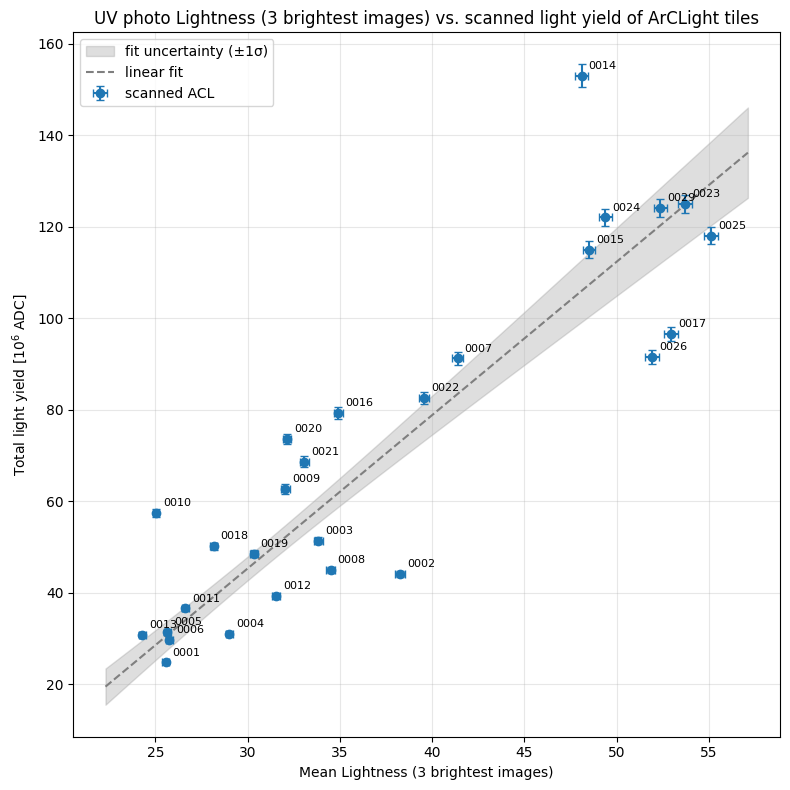

In [153]:
TOP_N = 3


def top_mean(r):
    return np.mean(np.sort(r["per_image_mean"])[-TOP_N:])


def top_error(r):
    if LIGHTNESS_REL_ERR is None:
        return np.std(np.sort(r["per_image_mean"])[-TOP_N:], ddof=1) / np.sqrt(TOP_N)
    return LIGHTNESS_REL_ERR * top_mean(r)


L_top = np.array([top_mean(results[t]) for t in scanned])
L_top_err = np.array([top_error(results[t]) for t in scanned])

pearson_top = stats.pearsonr(L_top, ly)
spearman_top = stats.spearmanr(L_top, ly)
s0, i0 = np.polyfit(L_top, ly, 1)
fit_top = odr.ODR(odr.RealData(L_top, ly, sx=L_top_err, sy=ly_err),
                  odr.Model(lambda b, x: b[0] * x + b[1]), beta0=[s0, i0]).run()
(slope_top, intercept_top), (slope_top_err, intercept_top_err) = fit_top.beta, fit_top.sd_beta
residual_std_top = np.sqrt(np.sum((ly - (slope_top * L_top + intercept_top)) ** 2) / ndf)

print(f"{'':<28s} {'all 7 images':>14s} {f'{TOP_N} brightest':>14s}")
print(f"{'Pearson r':<28s} {pearson.statistic:14.3f} {pearson_top.statistic:14.3f}")
print(f"{'Spearman rho':<28s} {spearman.statistic:14.3f} {spearman_top.statistic:14.3f}")
print(f"{'residual std [10^6 ADC]':<28s} {residual_std / scale:14.1f} {residual_std_top / scale:14.1f}")
print(f"{'slope [10^6 ADC per L]':<28s} {slope / scale:14.2f} {slope_top / scale:14.2f}")
print(f"{'intercept [10^6 ADC]':<28s} {intercept / scale:14.1f} {intercept_top / scale:14.1f}")
if "run_images" in globals():
    print(f"{'stability test: std of mean':<28s} {run_images.mean(axis=1).std(ddof=1):14.2f} "
          f"{np.sort(run_images, axis=1)[:, -TOP_N:].mean(axis=1).std(ddof=1):14.2f}")
print(f"\n{TOP_N}-brightest fit: LY = ({slope_top:.3e} ± {slope_top_err:.1e}) * L "
      f"+ ({intercept_top:.3e} ± {intercept_top_err:.1e}),  reduced chi2 = {fit_top.res_var:.2f}")

x_top = np.linspace(L_top.min() - 2, L_top.max() + 2, 100)
fig, ax = plt.subplots(figsize=(8, 8))
ax.errorbar(L_top, ly / scale, xerr=L_top_err, yerr=ly_err / scale, fmt="o", capsize=3, color="tab:blue",
            label="scanned ACL")
for t, l, y in zip(scanned, L_top, ly):
    ax.annotate(results[t]["acl"].replace("ACL-26-", ""), (l, y / scale), textcoords="offset points",
                xytext=(5, 5), fontsize=8)
y_top = slope_top * x_top + intercept_top
band_top = fit_band(fit_top, x_top)
ax.fill_between(x_top, (y_top - band_top) / scale, (y_top + band_top) / scale, color="tab:gray", alpha=0.25,
                label="fit uncertainty (±1σ)")
ax.plot(x_top, y_top / scale, "--", color="tab:gray", label="linear fit")
ax.set_xlabel(f"Mean Lightness ({TOP_N} brightest images)")
ax.set_ylabel("Total light yield [$10^6$ ADC]")
ax.set_title(f"UV photo Lightness ({TOP_N} brightest images) vs. scanned light yield of ArCLight tiles")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Retake check

Compares a retake of a tile with its original measurement from the manifest, to check whether a surprising result is a measurement mistake. The order of the 7 LED configurations isn't always the same between runs, so configurations are paired by brightness rank (darkest with darkest, and so on), which doesn't change the tile mean. The error on the difference is √2 × the run-to-run spread from the stability test (section 7), scaled to this tile's Lightness. If the stability test hasn't been run, it falls back to the spread of the 7 paired differences, which underestimates the error because it misses shifts common to all 7 images (e.g. placement).

For scanned tiles it also prints the Lightness the tile would need to sit exactly on the fit line from section 8. If the retake difference is much smaller than that gap, the outlier is not a photo problem.

In [154]:
RETAKES = {  # tile as named in the manifest (ACL or DSG id) -> (first image, last image) of the retake
    "ACL-26-0026": (7583, 7589),
    "ACL-26-0017": (7591, 7597),
}
RETAKE_FOLDER = DEFAULT_FOLDER

for name, (first, last) in RETAKES.items():
    key = next(k for k in results if name in k)
    orig = np.array(results[key]["per_image_mean"])
    paths = tile_paths(RETAKE_FOLDER, first, last)
    r0, r1, c0, c1 = CROPS.get(key) or detect_tile_box(paths)
    retake = np.array([lightness(np.asarray(Image.open(p))[r0:r1, c0:c1]).mean() for p in paths])

    diffs = np.sort(retake) - np.sort(orig)
    delta = diffs.mean()
    if "stab_rel" in globals():
        delta_err = np.sqrt(2) * stab_rel * orig.mean()
        err_source = "stability test"
    else:
        delta_err = diffs.std(ddof=1) / np.sqrt(len(diffs))
        err_source = "spread of paired configurations, underestimates the error"
    n_sigma = abs(delta) / delta_err
    verdict = "consistent" if n_sigma < 2 else "SIGNIFICANT difference"

    print(f"{key}")
    print(f"  original {results[key]['images']}:  mean L = {orig.mean():6.2f}   sorted: " + " ".join(f"{v:5.1f}" for v in np.sort(orig)))
    print(f"  retake   {first}-{last}:  mean L = {retake.mean():6.2f}   sorted: " + " ".join(f"{v:5.1f}" for v in np.sort(retake)))
    print(f"  retake - original: {delta:+.2f} ± {delta_err:.2f}  ({n_sigma:.1f} sigma, {verdict}; error from {err_source})")
    acl = results[key]["acl"]
    if acl in LIGHT_YIELD:
        L_on_line = (LIGHT_YIELD[acl] - intercept) / slope
        print(f"  to sit on the fit line this tile would need L = {L_on_line:.1f}, "
              f"i.e. {L_on_line - orig.mean():+.1f} from the original measurement")
    print()

ACL-26-0026 (DSG-36)
  original 7381-7387:  mean L =  41.58   sorted:  30.1  30.8  36.0  38.4  44.7  51.0  60.0
  retake   7583-7589:  mean L =  41.39   sorted:  29.5  31.3  35.7  38.5  44.3  50.8  59.7
  retake - original: -0.18 ± 0.43  (0.4 sigma, consistent; error from stability test)
  to sit on the fit line this tile would need L = 34.4, i.e. -7.2 from the original measurement

ACL-26-0017 (DSG-22)
  original 7349-7355:  mean L =  42.79   sorted:  30.6  32.3  37.8  39.9  46.3  52.5  60.0
  retake   7591-7597:  mean L =  42.33   sorted:  29.7  32.3  37.3  39.9  45.6  51.7  59.8
  retake - original: -0.45 ± 0.44  (1.0 sigma, consistent; error from stability test)
  to sit on the fit line this tile would need L = 35.6, i.e. -7.2 from the original measurement



## 10. Figures for slides

Saved as PNGs (200 dpi) in `FIG_DIR`.

1. One complete QC measurement of a tile: the room-light label photo and the 7 LED configurations. `CONFIG_LABELS` describes the configurations in the order they were taken for `MONTAGE_TILE` ("top/bottom/left/right" as seen by the camera); the order differs between some tiles, so check the labels if you change the tile.
2. For each tile in `COMPARE`: the photo with all four LED strips on, next to the per-pixel Lightness averaged over all 7 images (the map behind the tile mean used in the correlation). Both are cropped to the same detected tile area, and the Lightness maps share one colour scale. The all-on image differs between tiles because the shooting order varies, so it is listed explicitly per tile.

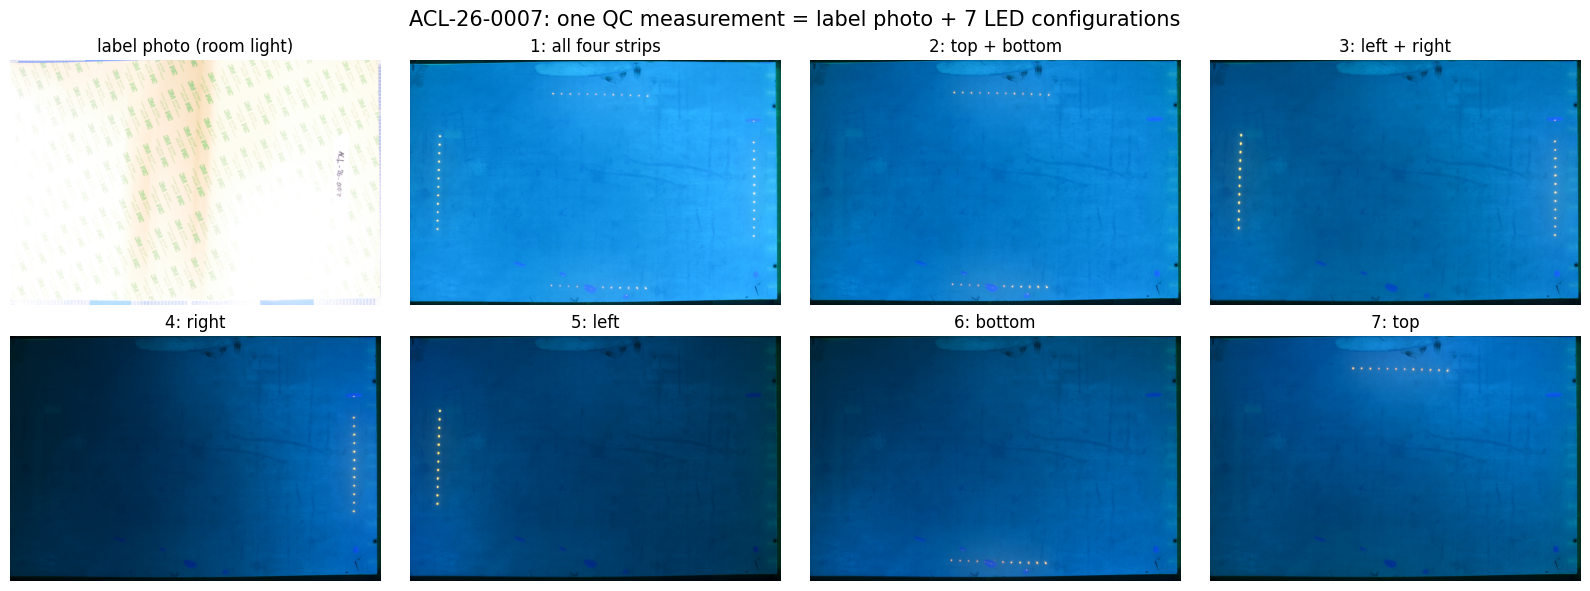

In [155]:
FIG_DIR = "/Users/johannes/Desktop/Master Thesis/figures"
MONTAGE_TILE = "ACL-26-0007"
MONTAGE_LABEL_IMAGE = 7412  # room-light label photo taken before the sequence
CONFIG_LABELS = ["all four strips", "top + bottom", "left + right", "right", "left", "bottom", "top"]

key = next(k for k in results if MONTAGE_TILE in k)
first, last = map(int, results[key]["images"].split("-"))
numbers = [MONTAGE_LABEL_IMAGE] + list(range(first, last + 1))
titles = ["label photo (room light)"] + [f"{k}: {label}" for k, label in enumerate(CONFIG_LABELS, start=1)]

fig, axes = plt.subplots(2, 4, figsize=(16, 5.8), layout="constrained")
for ax, n, title in zip(axes.flat, numbers, titles):
    ax.imshow(Image.open(os.path.join(IMAGE_DIR, f"STT_{n}.JPG")).reduce(4))
    ax.set_title(title, fontsize=12)
    ax.axis("off")
fig.suptitle(f"{MONTAGE_TILE}: one QC measurement = label photo + 7 LED configurations", fontsize=15)
fig.savefig(os.path.join(FIG_DIR, f"uv_photo_configurations_{MONTAGE_TILE}.png"), dpi=200)
plt.show()

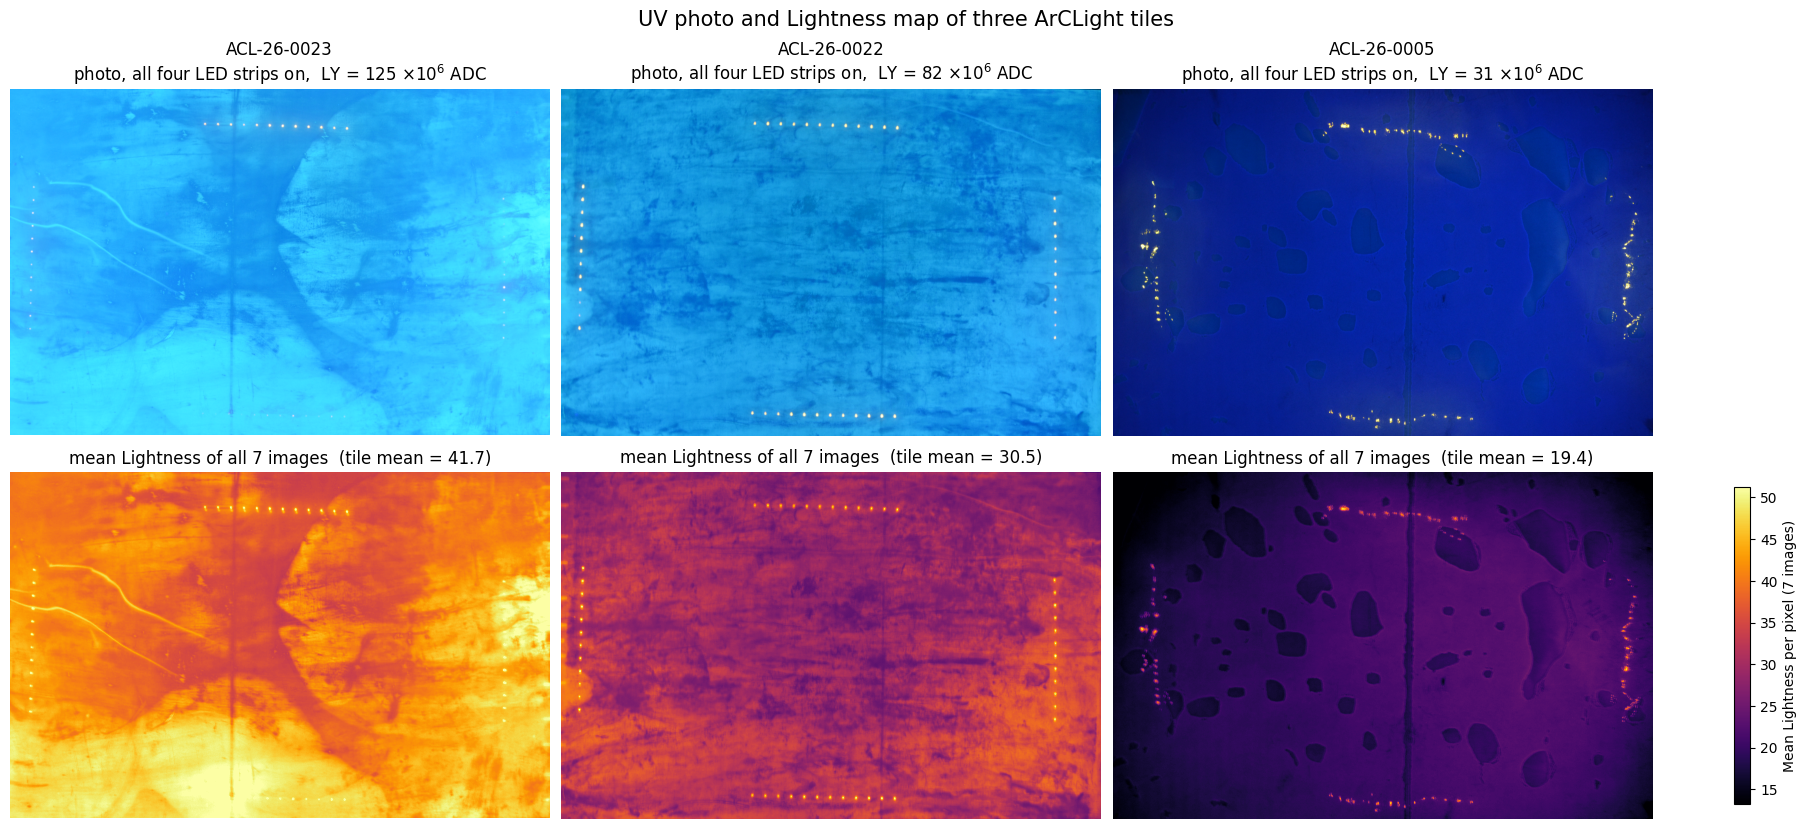

In [156]:
COMPARE = [  # (tile, image with all four LED strips on), checked by detecting the lit LED strips
    ("ACL-26-0023", 7324),
    ("ACL-26-0022", 7322),
    ("ACL-26-0005", 7462),
]

panels = []
for tile, n in COMPARE:
    r = results[next(k for k in results if tile in k)]
    r0, r1, c0, c1 = r["box"]
    photo = np.asarray(Image.open(os.path.join(IMAGE_DIR, f"STT_{n}.JPG")))[r0:r1, c0:c1]
    photo = photo[::SMOOTH_DOWNSAMPLE, ::SMOOTH_DOWNSAMPLE]  # same crop and sampling as the Lightness map
    panels.append((tile, n, r, photo))
vmin, vmax = np.percentile(np.concatenate([r["smooth"].ravel() for _, _, r, _ in panels]), [0.5, 99.5])

fig, axes = plt.subplots(2, len(panels), figsize=(6 * len(panels), 8.2), layout="constrained")
for col, (tile, n, r, photo) in zip(axes.T, panels):
    ly_text = f"LY = {LIGHT_YIELD[r['acl']] / 1e6:.0f}" + r" $\times 10^6$ ADC" if r["acl"] in LIGHT_YIELD else "not scanned"
    col[0].imshow(photo)
    col[0].set_title(f"{tile}\nphoto, all four LED strips on,  {ly_text}", fontsize=12)
    im = col[1].imshow(r["smooth"], cmap="inferno", vmin=vmin, vmax=vmax)
    col[1].set_title(f"mean Lightness of all 7 images  (tile mean = {r['mean']:.1f})", fontsize=12)
    for ax in col:
        ax.axis("off")
fig.colorbar(im, ax=axes[1, :], label="Mean Lightness per pixel (7 images)", shrink=0.9)
fig.suptitle("UV photo and Lightness map of three ArCLight tiles", fontsize=15)
fig.savefig(os.path.join(FIG_DIR, "uv_photo_lightness_comparison.png"), dpi=200)
plt.show()


## 11. Single image with all four LED strips on

Would one photo per tile be enough? Here each tile is represented only by its image with all four LED strips on, instead of the mean of 7.

**Finding the all-on image:** all four strips together give the sum of the top+bottom and left+right light, so the all-on image is each tile's brightest image. This was checked against direct detection of the lit LED strips for the 29 tiles where the strips are visible, and agreed in every case. For the brightest tiles (0025, DSG-43, DSG-44) the LED dots can't be seen against the coating, so the rule is the only handle there. If a tile is ever photographed differently, put its all-on image number into `ALL_ON_OVERRIDE`.

**Error on Lightness:** from the stability test, using the brightest image of each repeat (if section 7 has been run); otherwise `LIGHTNESS_REL_ERR`.

**Clipping:** the all-on image is the one most affected by the blue channel saturating. Tiles where more than `CLIP_LIMIT` of the tile area is clipped in the all-on image are drawn as hollow markers.

In [157]:
ALL_ON_OVERRIDE = {}  # e.g. {"ACL-26-0025": 7276} to set the all-on image of a tile by hand
CLIP_LIMIT = 10  # [%] of tile pixels with the blue channel at the ceiling
L_BINS = np.arange(0, 101, 1)

all_on = {}
for key, r in results.items():
    first, last = map(int, r["images"].split("-"))
    override = next((n for t, n in ALL_ON_OVERRIDE.items() if t in key), None)
    n = override if override is not None else first + int(np.argmax(r["per_image_mean"]))
    r0, r1, c0, c1 = r["box"]
    rgb_on = np.asarray(Image.open(os.path.join(IMAGE_DIR, f"STT_{n}.JPG")))[r0:r1, c0:c1]
    L_on = lightness(rgb_on)
    all_on[key] = {
        "image": n,
        "mean": L_on.mean(),
        "median": np.median(L_on),
        "clipped": 100 * np.mean(rgb_on[..., 2] >= 250),
        "hist": np.histogram(L_on, bins=L_BINS)[0],
    }

if "run_images" in globals():
    brightest = run_images.max(axis=1)
    ALL_ON_REL_ERR = brightest.std(ddof=1) / brightest.mean()
    err_source = f"stability test, brightest image of each repeat ({len(brightest)} repeats)"
else:
    ALL_ON_REL_ERR = LIGHTNESS_REL_ERR or 0.007
    err_source = "LIGHTNESS_REL_ERR (stability test not loaded)"
print(f"relative Lightness error of a single all-on image: {100 * ALL_ON_REL_ERR:.2f}%  ({err_source})\n")

print(f"{'tile':<24s} {'image':>6s} {'mean L':>7s} {'median L':>9s} {'clipped %':>10s}   {'7-image mean':>12s}")
for key, a in all_on.items():
    print(f"{key:<24s} {a['image']:>6d} {a['mean']:7.2f} {a['median']:9.2f} {a['clipped']:10.1f}   {results[key]['mean']:12.2f}")

relative Lightness error of a single all-on image: 0.47%  (stability test, brightest image of each repeat (10 repeats))

tile                      image  mean L  median L  clipped %   7-image mean
DSG-01                     7612   28.14     29.41        0.0          17.97
DSG-02                     7616   32.51     32.94        0.0          17.05
DSG-03                     7629   40.15     40.98        0.0          25.28
DSG-04                     7631   38.45     39.61        0.0          22.82
DSG-05                     7643   28.29     29.22        0.0          20.26
DSG-06                     7648   35.47     36.67        0.0          21.50
DSG-19                     7660   33.66     34.31        0.0          20.78
DSG-23                     7664   38.38     42.94       15.1          22.76
ACL-26-0001 (DSG-07)       7478   29.21     29.41        0.0          19.47
ACL-26-0002 (DSG-11)       7427   45.99     46.27        7.8          29.72
ACL-26-0003 (DSG-10)       7285   46.22    

                                all 7 images  all-on image
Pearson r                              0.886         0.889
Spearman rho                           0.869         0.880
residual std [10^6 ADC]                 17.7          17.9

all-on fit: LY = (2.772e+06 ± 3.3e+05) * L + (-5.757e+07 ± 1.2e+07)
10 of 27 scanned tiles have > 10% of the tile clipped in the all-on image: 0003, 0007, 0014, 0015, 0017, 0023, 0024, 0025, 0026, 0029
Pearson r using only the 17 unclipped tiles: 0.686


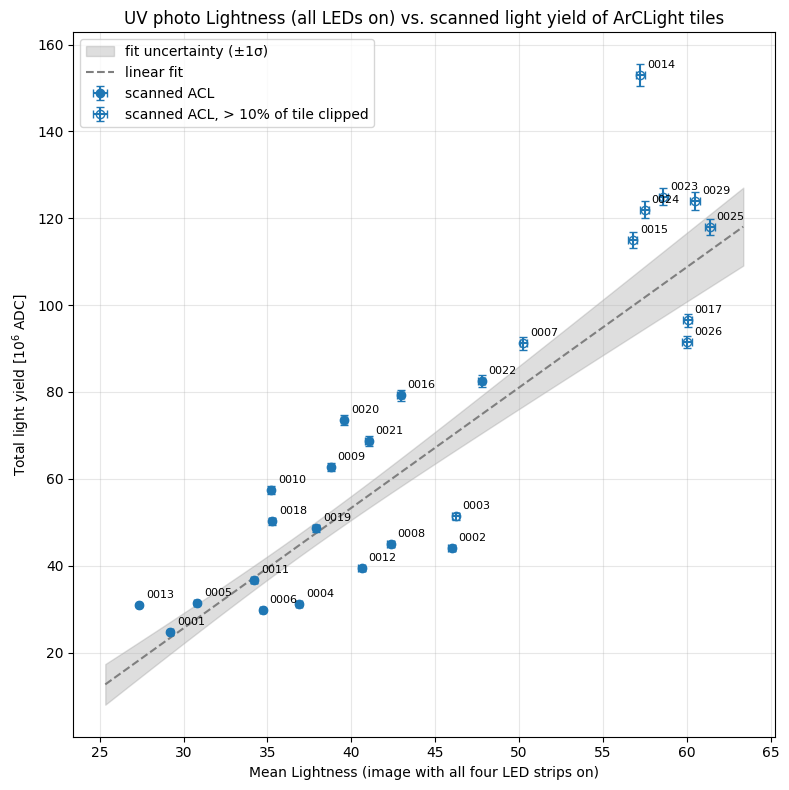

In [158]:
L_on = np.array([all_on[t]["mean"] for t in scanned])
L_on_err = ALL_ON_REL_ERR * L_on
clipped = np.array([all_on[t]["clipped"] > CLIP_LIMIT for t in scanned])

pearson_on = stats.pearsonr(L_on, ly)
spearman_on = stats.spearmanr(L_on, ly)
s0, i0 = np.polyfit(L_on, ly, 1)
fit_on = odr.ODR(odr.RealData(L_on, ly, sx=L_on_err, sy=ly_err),
                 odr.Model(lambda b, x: b[0] * x + b[1]), beta0=[s0, i0]).run()
(slope_on, intercept_on), (slope_on_err, intercept_on_err) = fit_on.beta, fit_on.sd_beta
residual_std_on = np.sqrt(np.sum((ly - (slope_on * L_on + intercept_on)) ** 2) / ndf)

L_unclipped = L_on[~clipped]
pearson_on_unclipped = stats.pearsonr(L_unclipped, ly[~clipped]) if len(L_unclipped) >= 3 else None

print(f"{'':<30s} {'all 7 images':>13s} {'all-on image':>13s}")
print(f"{'Pearson r':<30s} {pearson.statistic:13.3f} {pearson_on.statistic:13.3f}")
print(f"{'Spearman rho':<30s} {spearman.statistic:13.3f} {spearman_on.statistic:13.3f}")
print(f"{'residual std [10^6 ADC]':<30s} {residual_std / scale:13.1f} {residual_std_on / scale:13.1f}")
print(f"\nall-on fit: LY = ({slope_on:.3e} ± {slope_on_err:.1e}) * L + ({intercept_on:.3e} ± {intercept_on_err:.1e})")
print(f"{clipped.sum()} of {len(scanned)} scanned tiles have > {CLIP_LIMIT}% of the tile clipped in the all-on image: "
      + ", ".join(results[t]["acl"].replace("ACL-26-", "") for t, c in zip(scanned, clipped) if c))
if pearson_on_unclipped is not None:
    print(f"Pearson r using only the {len(L_unclipped)} unclipped tiles: {pearson_on_unclipped.statistic:.3f}")

x_on = np.linspace(L_on.min() - 2, L_on.max() + 2, 100)
y_on = slope_on * x_on + intercept_on
band_on = fit_band(fit_on, x_on)
fig, ax = plt.subplots(figsize=(8, 8))
ax.fill_between(x_on, (y_on - band_on) / scale, (y_on + band_on) / scale, color="tab:gray", alpha=0.25,
                label="fit uncertainty (±1σ)")
ax.plot(x_on, y_on / scale, "--", color="tab:gray", label="linear fit")
for mask, mfc, label in [(~clipped, "tab:blue", "scanned ACL"),
                         (clipped, "none", f"scanned ACL, > {CLIP_LIMIT}% of tile clipped")]:
    if mask.any():
        ax.errorbar(L_on[mask], ly[mask] / scale, xerr=L_on_err[mask], yerr=ly_err[mask] / scale, fmt="o",
                    mfc=mfc, capsize=3, color="tab:blue", label=label)
for t, l, y in zip(scanned, L_on, ly):
    ax.annotate(results[t]["acl"].replace("ACL-26-", ""), (l, y / scale), textcoords="offset points",
                xytext=(5, 5), fontsize=8)
ax.set_xlabel("Mean Lightness (image with all four LED strips on)")
ax.set_ylabel("Total light yield [$10^6$ ADC]")
ax.set_title("UV photo Lightness (all LEDs on) vs. scanned light yield of ArCLight tiles")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "uv_photo_allon_correlation.png"), dpi=200)
plt.show()

### Per-pixel Lightness distribution in the all-on images

Distribution of the Lightness of every pixel in the tile area of each all-on image. Left: all tiles, coloured by their mean Lightness. Right: three example tiles with their mean (dashed) and median (dotted). The y-axis is the fraction of tile pixels per Lightness unit, so tiles of different area are comparable.

In these photos blue is always the strongest channel, and red close to 0, so Lightness ≈ blue/2. A pixel whose blue channel is at the ceiling (255) therefore has Lightness ≈ 50–60, not 100. Clipping shows up as a pile-up / sharp edge around there, not at the right end of the axis.

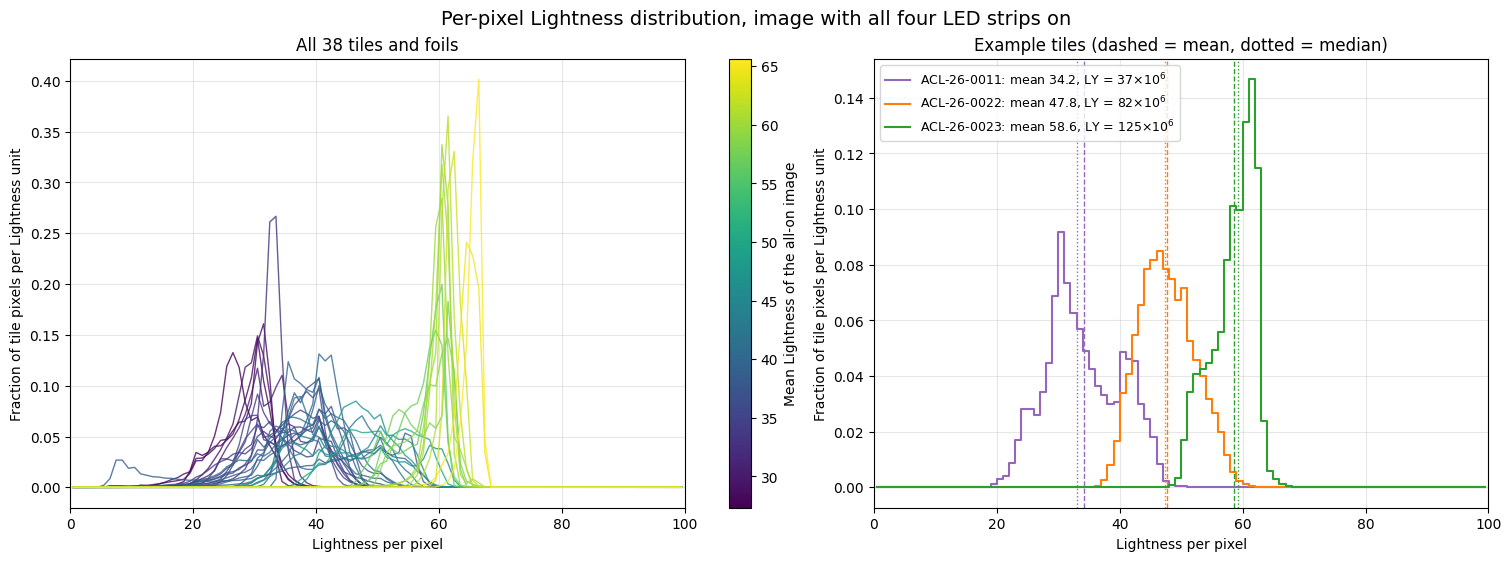

In [160]:
EXAMPLE_TILES = ["ACL-26-0011", "ACL-26-0022", "ACL-26-0023"]

centres = 0.5 * (L_BINS[1:] + L_BINS[:-1])
means = np.array([a["mean"] for a in all_on.values()])
norm = plt.Normalize(means.min(), means.max())
cmap = plt.cm.viridis

fig, (ax_all, ax_ex) = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
for key, a in sorted(all_on.items(), key=lambda kv: kv[1]["mean"]):
    frac = a["hist"] / a["hist"].sum()
    ax_all.plot(centres, frac, color=cmap(norm(a["mean"])), lw=1, alpha=0.8)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax_all, label="Mean Lightness of the all-on image")
ax_all.set_title(f"All {len(all_on)} tiles and foils")

for color, tile in zip(["tab:purple", "tab:orange", "tab:green"], EXAMPLE_TILES):
    key = next(k for k in all_on if tile in k)
    a = all_on[key]
    ly_text = f", LY = {LIGHT_YIELD[results[key]['acl']] / 1e6:.0f}" + r"$\times10^6$" if results[key]["acl"] in LIGHT_YIELD else ""
    ax_ex.step(centres, a["hist"] / a["hist"].sum(), where="mid", color=color,
               label=f"{tile}: mean {a['mean']:.1f}{ly_text}")
    ax_ex.axvline(a["mean"], color=color, ls="--", lw=1)
    ax_ex.axvline(a["median"], color=color, ls=":", lw=1)
ax_ex.set_title("Example tiles (dashed = mean, dotted = median)")
ax_ex.legend(fontsize=9)

for ax in (ax_all, ax_ex):
    ax.set_xlabel("Lightness per pixel")
    ax.set_ylabel("Fraction of tile pixels per Lightness unit")
    ax.set_xlim(0, 100)
    ax.grid(alpha=0.3)
fig.suptitle("Per-pixel Lightness distribution, image with all four LED strips on", fontsize=14)
fig.savefig(os.path.join(FIG_DIR, "uv_photo_allon_pixel_distribution.png"), dpi=200)
plt.show()

## 12. RGB composition of the all-on images

Lightness = (max + min) / 2 of the three channels. If the minimum channel is always red and close to 0, Lightness is effectively just half of the maximum channel, and the minimum contributes almost nothing. This section checks that, pixel by pixel, in the all-on image of every tile (section 11), and compares how well each channel on its own tracks the scanned LY.

1. Table: for each tile the mean R, G, B, the share of pixels where red is the minimum and blue the maximum, and the share of Lightness that comes from the minimum channel.
2. Pixel distributions for four example tiles, as two figures: a 3D cloud of (R, G, B) per pixel (each point drawn in its own colour), and per-channel histograms.
3. Tile mean of each channel against LY, with the correlations next to Lightness.

In [161]:
CHANNELS = ["R", "G", "B"]

rgb_stats = {}
for key, a in all_on.items():
    r0, r1, c0, c1 = results[key]["box"]
    px = np.asarray(Image.open(os.path.join(IMAGE_DIR, f"STT_{a['image']}.JPG")))[r0:r1, c0:c1].reshape(-1, 3)
    mx, mn = px.max(axis=1).astype(float), px.min(axis=1).astype(float)
    rgb_stats[key] = {
        "mean": px.mean(axis=0),
        "min_is_R": 100 * np.mean(px.argmin(axis=1) == 0),
        "max_is_B": 100 * np.mean(px.argmax(axis=1) == 2),
        "min_share": 100 * mn.sum() / (mx.sum() + mn.sum()),  # share of Lightness coming from the min channel
        "hist": [np.bincount(px[:, c], minlength=256) for c in range(3)],
        "sample": px[np.random.default_rng(0).choice(len(px), 3000, replace=False)],
    }

print(f"{'tile':<24s} {'mean R':>7s} {'mean G':>7s} {'mean B':>7s} {'min=R %':>8s} {'max=B %':>8s} "
      f"{'min share of L %':>17s} {'LY [1e6]':>9s}")
for key, s in rgb_stats.items():
    acl = results[key]["acl"]
    ly_text = f"{LIGHT_YIELD[acl] / 1e6:9.1f}" if acl in LIGHT_YIELD else f"{'-':>9s}"
    print(f"{key:<24s} {s['mean'][0]:7.1f} {s['mean'][1]:7.1f} {s['mean'][2]:7.1f} {s['min_is_R']:8.1f} "
          f"{s['max_is_B']:8.1f} {s['min_share']:17.1f} {ly_text}")

tile                      mean R  mean G  mean B  min=R %  max=B %  min share of L %  LY [1e6]
DSG-01                      10.3    30.8   133.2     99.5     99.7               7.0         -
DSG-02                      11.4    20.2   154.4     99.8     99.9               6.8         -
DSG-03                      14.7    50.7   190.1     99.8     99.8               7.1         -
DSG-04                      13.4    42.1   182.7     99.7     99.8               6.8         -
DSG-05                       9.3    40.6   135.0     99.6     99.6               6.3         -
DSG-06                      11.7    37.5   169.2     99.6     99.7               6.4         -
DSG-19                      12.7    41.4   158.9     99.3     99.5               7.3         -
DSG-23                      14.6    43.8   181.2     99.6     99.6               7.3         -
ACL-26-0001 (DSG-07)         8.3    33.9   140.7     99.6     99.6               5.4      24.8
ACL-26-0002 (DSG-11)        16.6   120.4   218.0  

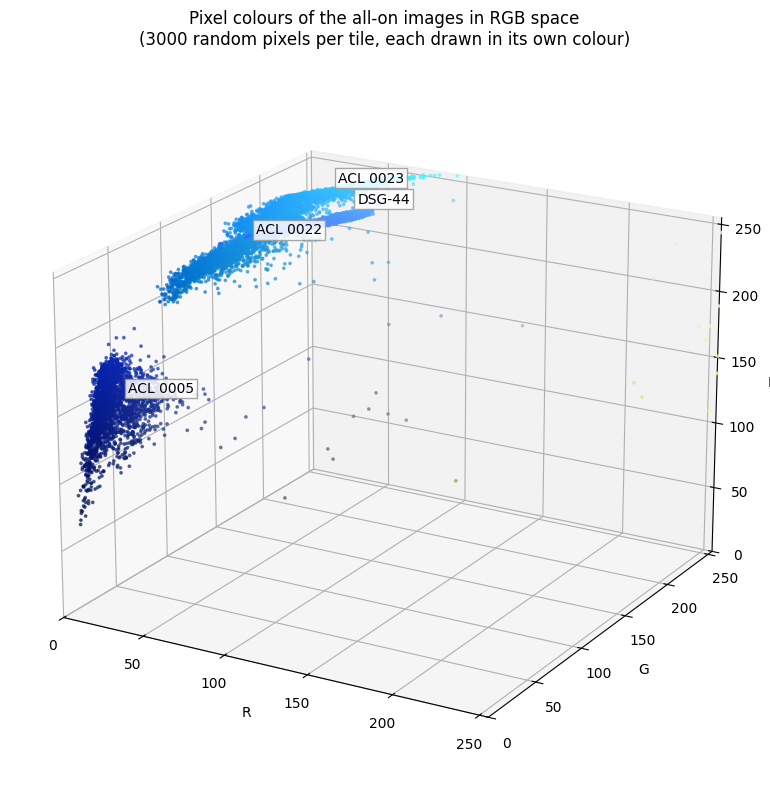

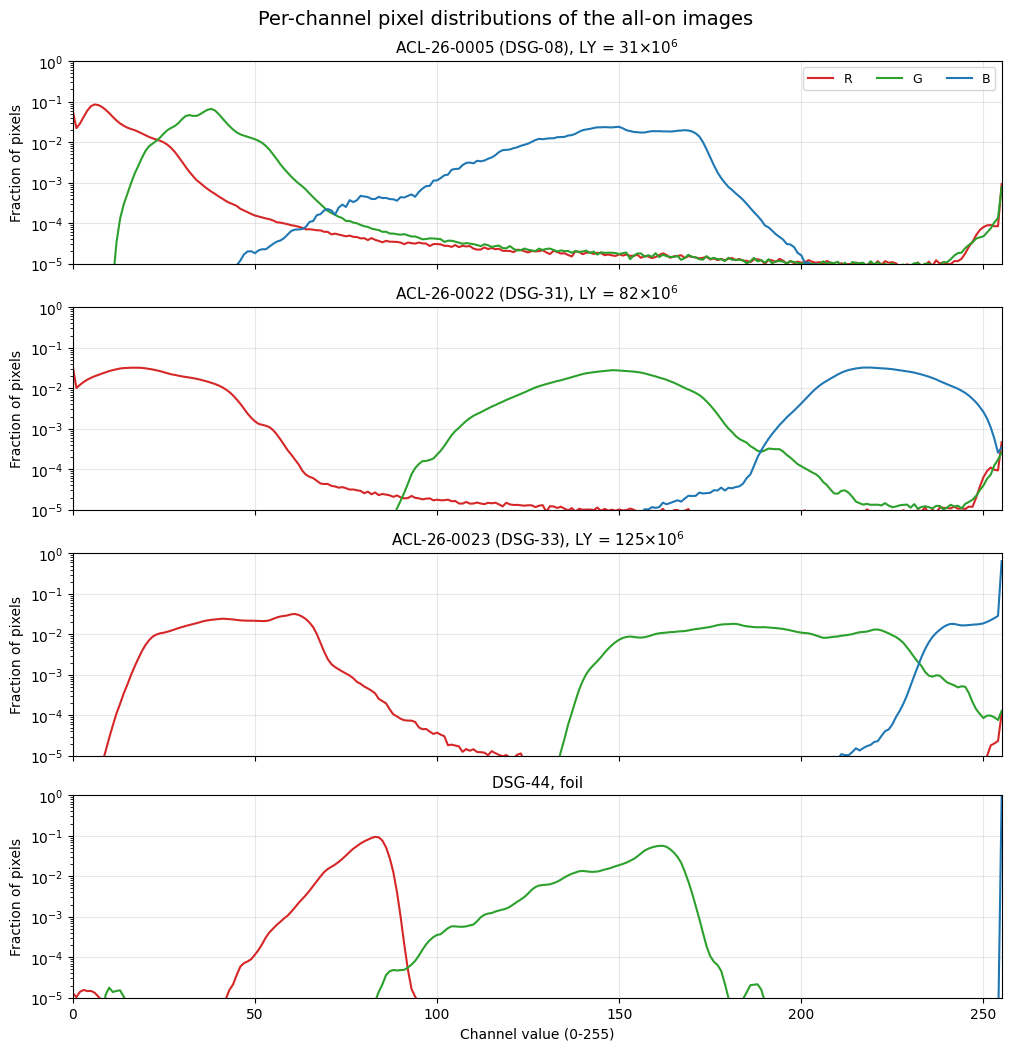

In [166]:
RGB_EXAMPLES = ["ACL-26-0005", "ACL-26-0022", "ACL-26-0023", "DSG-44"]
example_keys = [next(k for k in rgb_stats if tile in k) for tile in RGB_EXAMPLES]


def example_label(key):
    acl = results[key]["acl"]
    return f"{key}, LY = {LIGHT_YIELD[acl] / 1e6:.0f}" + r"$\times10^6$" if acl in LIGHT_YIELD else f"{key}, foil"


# Figure 1: pixel colours in RGB space
fig = plt.figure(figsize=(9, 8), layout="constrained")
ax3d = fig.add_subplot(projection="3d")
for tile, key in zip(RGB_EXAMPLES, example_keys):
    sample = rgb_stats[key]["sample"]
    ax3d.scatter(sample[:, 0], sample[:, 1], sample[:, 2], c=sample / 255, s=3, alpha=0.6)
    centre = rgb_stats[key]["mean"]
    ax3d.text(centre[0] + 25, centre[1] - 25, centre[2] + 25, tile.replace("ACL-26-", "ACL "), fontsize=10,
              zorder=10, bbox=dict(facecolor="white", edgecolor="0.6", alpha=0.85, pad=2))
ax3d.set_xlabel("R")
ax3d.set_ylabel("G")
ax3d.set_zlabel("B")
for setter in (ax3d.set_xlim, ax3d.set_ylim, ax3d.set_zlim):
    setter(0, 255)
ax3d.view_init(elev=20, azim=-60)
ax3d.set_title("Pixel colours of the all-on images in RGB space\n(3000 random pixels per tile, each drawn in its own colour)")
fig.savefig(os.path.join(FIG_DIR, "uv_photo_allon_rgb_3d.png"), dpi=200)
plt.show()

# Figure 2: per-channel distributions
levels = np.arange(256)
fig, axes = plt.subplots(len(example_keys), 1, figsize=(10, 2.6 * len(example_keys)), sharex=True,
                         layout="constrained")
for ax, key in zip(axes, example_keys):
    for c, color in enumerate(["tab:red", "tab:green", "tab:blue"]):
        h = rgb_stats[key]["hist"][c]
        ax.plot(levels, h / h.sum(), color=color, label=CHANNELS[c])
    ax.set_title(example_label(key), fontsize=11)
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 1)
    ax.set_ylabel("Fraction of pixels")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=9, ncol=3)
axes[-1].set_xlim(0, 255)
axes[-1].set_xlabel("Channel value (0-255)")
fig.suptitle("Per-channel pixel distributions of the all-on images", fontsize=14)
fig.savefig(os.path.join(FIG_DIR, "uv_photo_allon_rgb_histograms.png"), dpi=200)
plt.show()


quantity (all-on image)   Pearson r  Spearman rho
Lightness                     0.889         0.880
R                             0.827         0.664
G                             0.911         0.935
B                             0.881         0.888
(R+G+B)/3                     0.918         0.916


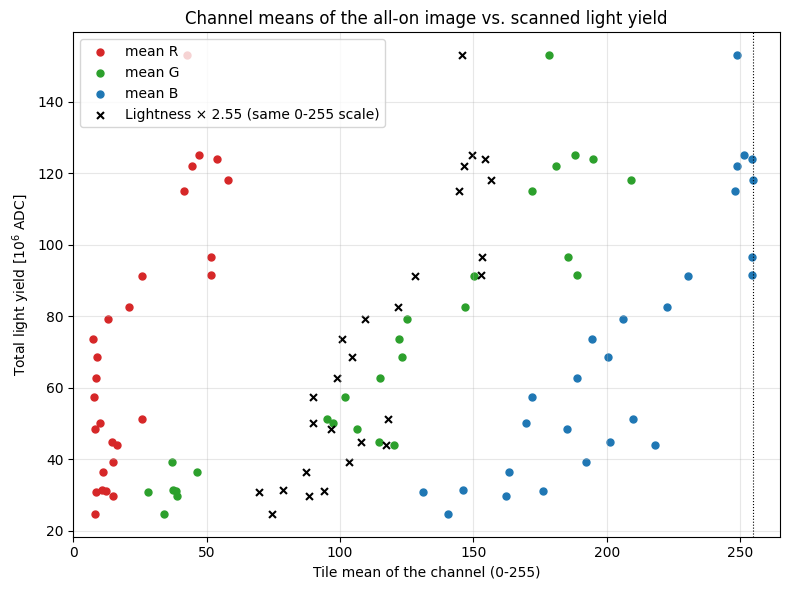

In [163]:
means = {c: np.array([rgb_stats[t]["mean"][i] for t in scanned]) for i, c in enumerate(CHANNELS)}
candidates = {"Lightness": L_on, "R": means["R"], "G": means["G"], "B": means["B"],
              "(R+G+B)/3": (means["R"] + means["G"] + means["B"]) / 3}
print(f"{'quantity (all-on image)':<24s} {'Pearson r':>10s} {'Spearman rho':>13s}")
for name, values in candidates.items():
    print(f"{name:<24s} {stats.pearsonr(values, ly).statistic:10.3f} {stats.spearmanr(values, ly).statistic:13.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
for c, color in zip(CHANNELS, ["tab:red", "tab:green", "tab:blue"]):
    ax.scatter(means[c], ly / scale, color=color, s=25, label=f"mean {c}")
ax.scatter(2.55 * L_on, ly / scale, marker="x", color="k", s=25, label="Lightness × 2.55 (same 0-255 scale)")
ax.axvline(255, color="k", lw=0.8, ls=":")
ax.set_xlabel("Tile mean of the channel (0-255)")
ax.set_ylabel("Total light yield [$10^6$ ADC]")
ax.set_title("Channel means of the all-on image vs. scanned light yield")
ax.set_xlim(0, 265)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "uv_photo_allon_channels_vs_ly.png"), dpi=200)
plt.show()

## Notes / things worth trying next

- **Shoot RAW, not JPEG, if the camera supports it.** JPEG is 8-bit and gamma-corrected; a Nikon D7000 (which these images are from) can write 12/14-bit NEF RAW files with much more headroom before clipping. That would directly address the "does the camera saturate" question instead of just detecting it after the fact.
- **Keep the zoom ring fixed (tape it).** So far every session had a different focal length (18 mm on Oct 7, 22 mm on the morning of Oct 8, 21 mm in the afternoon), so the camera sees a different fraction of the tile at a different pixel scale. Automatic tile detection compensates for position, but at 22 mm the tile edges are outside the frame, so those tiles are measured over a smaller area than the others.
- **Flat-field / normalize for illumination fall-off.** The sample images show a strong central hotspot that fades toward the edges — that's the illumination pattern, not the tile. Photographing a uniform reference (or a blank/no-plate shot) under the same lighting and dividing each plate image by it would separate "how bright is the LED here" from "how well does this tile convert light."
- **Fixed manual exposure across all plates.** The new-setup images all use 1/1.3 s, f/8, ISO 400 — good, keep it that way so lightness values are comparable session to session; auto-exposure would break the correlation to LY.
- **Sum vs. mean lightness across the 7 images** — try both against the scanner LY numbers and see which correlates better.
- **Compare the blue channel alone vs. HSL Lightness.** TPB emission peaks around 425 nm (blue); the blue channel alone might track photon yield more directly than a metric that mixes in red/green.
- I looked at one sample from each of the `with light diffuse` and `without light diffuse` folders on the card: the diffuse-light one is almost entirely blown out white across the whole frame, while the non-diffuse one has a strong localized hotspot but more usable dynamic range elsewhere. Worth running the saturation-fraction check above across both folders in bulk before deciding which illumination setup the new frame should use.